## Cell 1: Kernel ও dataset path


In [3]:

import importlib.util, subprocess, sys, os, json, time, hashlib, gc, platform
from pathlib import Path
from datetime import datetime
import xml.etree.ElementTree as ET

if importlib.util.find_spec('tensorflow') is None:
    raise RuntimeError('এই kernel-এ TensorFlow নেই। আপনার আগের training notebook-এর kernel নির্বাচন করুন।')
for module, package in [('numpy','numpy'), ('pandas','pandas'), ('PIL','Pillow'),
                        ('sklearn','scikit-learn'), ('matplotlib','matplotlib'),
                        ('skimage','scikit-image'), ('lime','lime')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import precision_recall_fscore_support, f1_score, multilabel_confusion_matrix
import tensorflow as tf
from tensorflow import keras
from skimage.segmentation import slic
from lime import lime_image
from IPython.display import display


VOC_ROOT = Path(r'D:\LIME\VOCdevkit\VOC2012')
if not (VOC_ROOT/'ImageSets'/'Action').is_dir():
    alternatives = [Path(p) for p in [r'M:\LIME\VOCdevkit\VOC2012',
        '/mnt/d/LIME/VOCdevkit/VOC2012', '/mnt/m/LIME/VOCdevkit/VOC2012']]
    VOC_ROOT = next((p for p in alternatives if (p/'ImageSets'/'Action').is_dir()), VOC_ROOT)
if not (VOC_ROOT/'ImageSets'/'Action').is_dir():
    raise FileNotFoundError(f'VOC2012 folder পাওয়া যায়নি: {VOC_ROOT}. উপরের VOC_ROOT ঠিক করুন।')

CLASSES = ['jumping','phoning','playinginstrument','reading','ridingbike',
           'ridinghorse','running','takingphoto','usingcomputer','walking']
MODELS = ['MobileNetV2','ResNet50','EfficientNetB0']
SEED = 42
SIZE = 224
MARGIN = 0.10
EPOCHS = 15                  
BATCH = 16                   
XAI_PER_CLASS = 2            
LIME_SAMPLES = 400           
IG_STEPS = 32
PATCH = 32
WORK = Path('VOC_XAI_Quick_Run').resolve()
CACHE = WORK/'cache'
RUN = WORK/('run_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
CACHE.mkdir(parents=True, exist_ok=True)
RUN.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)
for device in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(device, True)
    except RuntimeError: pass
CONFIG = dict(seed=SEED, size=SIZE, margin=MARGIN, epochs=EPOCHS, batch=BATCH,
    models=MODELS, xai_per_class=XAI_PER_CLASS, lime_samples=LIME_SAMPLES,
    ig_steps=IG_STEPS, patch=PATCH, augmentation='none; cached frozen features',
    scope='single-seed pilot, not a completed journal revision',
    dataset=str(VOC_ROOT.resolve()), tensorflow=tf.__version__, numpy=np.__version__,
    python=sys.version, platform=platform.platform(),
    visible_gpu=[str(d) for d in tf.config.list_physical_devices('GPU')])
(RUN/'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
print('ধাপ ১ শেষ। Dataset:', VOC_ROOT)
print('TensorFlow:', tf.__version__, '| GPU:', CONFIG['visible_gpu'])
print('ফলাফল এখানে থাকবে:', RUN)
print('এটি ১টি seed-এর pilot। আজ GPU setup বা TensorFlow upgrade করবেন না।')

ধাপ ১ শেষ। Dataset: D:\LIME\VOCdevkit\VOC2012
TensorFlow: 2.22.0-rc0 | GPU: []
ফলাফল এখানে থাকবে: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820
এটি ১টি seed-এর pilot। আজ GPU setup বা TensorFlow upgrade করবেন না।


## Cell 2: Dataset labels ও split যাচাই
Counts না মিললে training বন্ধ হবে। এটি অনুমান করে label বদলায় না।


In [4]:

def build_manifest(root):
    
    
    root = Path(root)
    rows, audit = [], []
    recovered_flags = 0

    def xml_binary(text, iid, pid, cls):
        value = str(text).strip().lower()
        if value in ('1','true'): return 1
        if value in ('0','false'): return 0
        raise ValueError(f'Invalid XML action flag: {iid}, person {pid}, {cls}={text!r}')

    for official_split in ['train','val']:
        persons = {}
        action_dir = root/'ImageSets'/'Action'
        for cls in CLASSES:
            p = action_dir/f'{cls}_{official_split}.txt'
            if not p.is_file(): raise FileNotFoundError(f'Missing action list: {p}')
            for line_no, line in enumerate(p.read_text().splitlines(), 1):
                fields = line.split()
                if not fields: continue
                if len(fields) != 3:
                    raise ValueError(f'{p}:{line_no}: image_id person_id label প্রয়োজন।')
                iid, pid, raw = fields[0], int(fields[1]), int(fields[2])
                if raw not in (-1,1):
                    raise ValueError(f'{p}:{line_no}: official action label ±1 প্রত্যাশিত; পাওয়া গেছে {raw}')
                row = persons.setdefault((iid,pid), {})
                label = int(raw == 1)
                if cls in row and row[cls] != label:
                    raise ValueError(f'Conflicting list labels: {iid}, person {pid}, {cls}')
                row[cls] = label

        
        
        split_file = action_dir/f'{official_split}.txt'
        if split_file.is_file():
            image_ids = sorted({line.split()[0] for line in split_file.read_text().splitlines() if line.split()})
            outside = set(i for i,p in persons)-set(image_ids)
            if outside:
                raise ValueError(f'Class list contains images outside official {official_split}.txt: {sorted(outside)[:3]}')
        else:
            image_ids = sorted({i for i,p in persons})

        for iid in image_ids:
            xml_path = root/'Annotations'/f'{iid}.xml'
            objects = ET.parse(xml_path).getroot().findall('object')
            for image_key,pid in [k for k in persons if k[0] == iid]:
                if not 1 <= pid <= len(objects) or objects[pid-1].findtext('name') != 'person':
                    raise ValueError(f'Invalid person object index: {iid}, {pid}')
            for pid,obj in enumerate(objects,1):
                if obj.findtext('name') != 'person': continue
                listed = persons.get((iid,pid), {})
                actions = obj.find('actions')
                if not listed and (actions is None or len(actions) == 0):
                    
                    audit.append(dict(image_id=iid, person_id=pid, official_split=official_split,
                        status='excluded_unannotated_person', details='No action annotation or list labels'))
                    continue
                row = dict(image_id=iid, person_id=pid, official_split=official_split, **listed)
                restored = []
                if actions is not None:
                    for c in CLASSES:
                        flag = actions.findtext(c)
                        if flag is None: continue
                        value = xml_binary(flag,iid,pid,c)
                        if c in row and row[c] != value:
                            raise ValueError(f'XML/list label mismatch: {iid}, person {pid}, {c}. Check that annotations and lists are from the same VOC release.')
                        if c not in row:
                            row[c] = value; recovered_flags += 1; restored.append(c)
                    other = actions.findtext('other')
                    if other is not None and xml_binary(other,iid,pid,'other') == 1:
                        if any(row.get(c) == 1 for c in CLASSES):
                            raise ValueError(f'Contradictory other/action labels: {iid}, person {pid}')
                        for c in CLASSES:
                            if c not in row:
                                row[c] = 0; recovered_flags += 1; restored.append(c+' (explicit other=1)')
                missing = [c for c in CLASSES if c not in row]
                if missing:
                    diagnostic = (f'Unresolved labels: {iid}, person {pid}: {missing}. '
                        f'XML actions: {ET.tostring(actions,encoding="unicode") if actions is not None else "NONE"}. '
                        'Labels were not guessed. Check annotation/list files for this person.')
                    if 'RUN' in globals():
                        (RUN/'label_diagnostic.txt').write_text(diagnostic,encoding='utf-8')
                    raise ValueError(diagnostic)
                if restored:
                    audit.append(dict(image_id=iid, person_id=pid, official_split=official_split,
                        status='recovered_from_XML', details=', '.join(restored)))
                box = obj.find('bndbox')
                if box is None: raise ValueError(f'Missing bounding box: {iid}, person {pid}')
                for k in ['xmin','ymin','xmax','ymax']:
                    row[k] = int(float(box.findtext(k)))
                if row['xmax'] < row['xmin'] or row['ymax'] < row['ymin']:
                    raise ValueError(f'Invalid bounding box: {iid}, person {pid}')
                image_path = root/'JPEGImages'/f'{iid}.jpg'
                if not image_path.is_file(): raise FileNotFoundError(str(image_path))
                row['image_path'] = str(image_path.resolve())
                st = image_path.stat()
                row['image_bytes'], row['image_mtime_ns'] = st.st_size, st.st_mtime_ns
                rows.append(row)
    if not rows: raise ValueError('No annotated person records found.')
    frame = pd.DataFrame(rows)
    if frame.duplicated(['image_id','person_id']).any():
        raise ValueError('Person record duplicated across official splits.')
    a = set(frame.loc[frame.official_split.eq('train'),'image_id'])
    b = set(frame.loc[frame.official_split.eq('val'),'image_id'])
    if a & b: raise ValueError('Official train/val image overlap পাওয়া গেছে।')
    audit_frame = pd.DataFrame(audit,columns=['image_id','person_id','official_split','status','details'])
    if 'RUN' in globals(): audit_frame.to_csv(RUN/'label_recovery_audit.csv',index=False)
    print(f'XML থেকে উদ্ধার করা action flags: {recovered_flags}')
    return frame

def assign_splits(frame, seed=42):
    frame = frame.copy()
    frame['split'] = 'heldout_official_val'
    tr = frame.loc[frame.official_split.eq('train')]
    for attempt in range(100):
        splitter = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=seed+attempt)
        a,b = next(splitter.split(tr, groups=tr.image_id))
        ia,ib = tr.index[a], tr.index[b]
        if (frame.loc[ia,CLASSES].sum().gt(0).all() and
            frame.loc[ib,CLASSES].sum().gt(0).all()): break
    else: raise ValueError('সব class-সহ train/dev split পাওয়া যায়নি।')
    frame.loc[ia,'split'], frame.loc[ib,'split'] = 'train','dev'
    sets = [set(frame.loc[frame.split.eq(s),'image_id'])
            for s in ['train','dev','heldout_official_val']]
    assert not any(sets[i] & sets[j] for i in range(3) for j in range(i))
    return frame, seed+attempt

df, split_seed = assign_splits(build_manifest(VOC_ROOT), SEED)
df.to_csv(RUN/'dataset_manifest.csv', index=False)
summary = df.groupby('split').agg(images=('image_id','nunique'), persons=('person_id','size'))
summary.to_csv(RUN/'split_counts.csv')
distribution = df.groupby('split')[CLASSES].sum().T
distribution.to_csv(RUN/'positive_action_counts.csv')
official = df.groupby('official_split').agg(images=('image_id','nunique'), persons=('person_id','size'))
display(official); display(summary); display(distribution)
expected = {'train': (2296,3134), 'val': (2292,3144)}
matches = all(tuple(official.loc[s,['images','persons']]) == v for s,v in expected.items())
print('Official counts match:', matches)
if not matches:
    print('STOP: আপনার dataset official পূর্ণ counts-এর সঙ্গে মিলছে না। আগে dataset files যাচাই করুন।')
    raise RuntimeError('Dataset counts mismatch; training বন্ধ রাখা হয়েছে।')
print('Multiple positive labels:', int((df[CLASSES].sum(axis=1)>1).sum()))
print('All-zero (other) persons:', int((df[CLASSES].sum(axis=1)==0).sum()))
print('Image overlap = 0 | split seed =', split_seed)
print('ধাপ ২ শেষ। এখন পরের cell চালান।')

XML থেকে উদ্ধার করা action flags: 608


,images,persons
official_split,,
train,2296,3134
val,2292,3144


,images,persons
split,,
dev,460,608
heldout_official_val,2292,3144
train,1836,2526


split,dev,heldout_official_val,train
jumping,54,248,193
phoning,59,229,169
playinginstrument,63,310,246
reading,62,266,202
ridingbike,49,289,240
ridinghorse,55,268,211
running,57,281,223
takingphoto,37,229,190
usingcomputer,45,239,192
walking,53,299,245


Official counts match: True
Multiple positive labels: 68
All-zero (other) persons: 1043
Image overlap = 0 | split seed = 42
ধাপ ২ শেষ। এখন পরের cell চালান।


## Cell 3: Person crops তৈরি
দেখানো crop-এ সঠিক person আছে কি না দেখুন। এটি 10% context margin ব্যবহার করে।


Crop 0/6278
Crop 500/6278
Crop 1000/6278
Crop 1500/6278
Crop 2000/6278
Crop 2500/6278
Crop 3000/6278
Crop 3500/6278
Crop 4000/6278
Crop 4500/6278
Crop 5000/6278
Crop 5500/6278
Crop 6000/6278


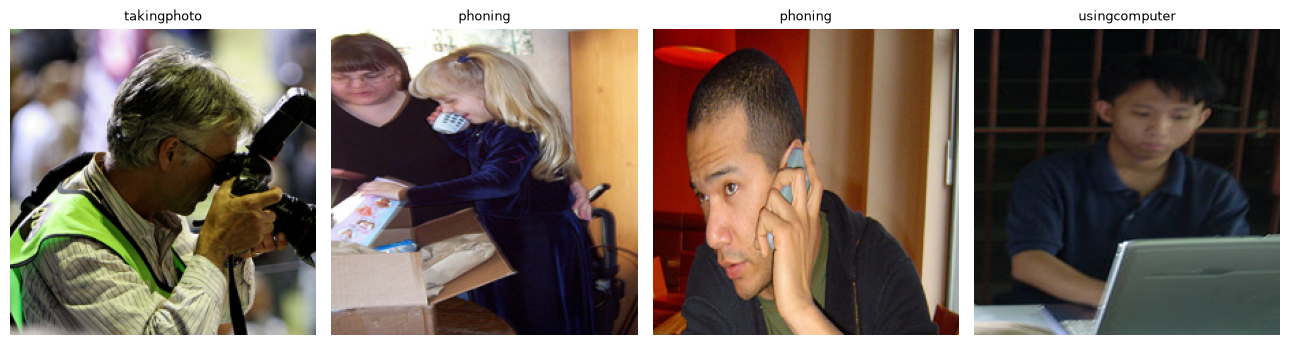

ধাপ ৩ শেষ। দেখুন crop-এ সঠিক ব্যক্তি আছে কি না। তারপর training cell চালান।


In [5]:

def crop_person(path, box, margin=.10, size=224):
    with Image.open(path) as source:
        im = source.convert('RGB')
        x1,y1,x2,y2 = map(float,box)
        
        left,top,right,bottom = x1-1,y1-1,x2,y2
        w,h = right-left,bottom-top
        bounds = (max(0,int(np.floor(left-margin*w))),
                  max(0,int(np.floor(top-margin*h))),
                  min(im.width,int(np.ceil(right+margin*w))),
                  min(im.height,int(np.ceil(bottom+margin*h))))
        if bounds[2] <= bounds[0] or bounds[3] <= bounds[1]:
            raise ValueError(f'Empty crop: {path}, {box}')
        resampling = getattr(Image,'Resampling',Image).BICUBIC
        return np.asarray(im.crop(bounds).resize((size,size),resampling), dtype=np.uint8)

def voc_ap(y, score):
    y = np.asarray(y,dtype=int); score = np.asarray(score,dtype=float)
    if y.sum() == 0: return float('nan')
    order = np.argsort(-score,kind='mergesort')
    tp = np.cumsum(y[order] == 1); fp = np.cumsum(y[order] == 0)
    recall = tp/y.sum(); precision = tp/np.maximum(tp+fp,1)
    mr = np.r_[0.,recall,1.]; mp = np.r_[0.,precision,0.]
    mp = np.maximum.accumulate(mp[::-1])[::-1]
    ix = np.where(mr[1:] != mr[:-1])[0]
    return float(np.sum((mr[ix+1]-mr[ix])*mp[ix+1]))

def ap_vector(y,p):
    return np.array([voc_ap(y[:,c],p[:,c]) for c in range(len(CLASSES))])

def classification_metrics(y,p,threshold=.5):
    pred = (p>=threshold).astype(int)
    pr,re,f,_ = precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    return dict(mAP=float(np.nanmean(ap_vector(y,p))),macro_precision=float(pr),
        macro_recall=float(re),macro_F1=float(f),
        micro_F1=float(f1_score(y,pred,average='micro',zero_division=0)))

crop_key = hashlib.sha256((df.to_csv(index=False)+json.dumps(dict(size=SIZE,margin=MARGIN,
    resize='PIL BICUBIC',pillow=Image.__version__))).encode()).hexdigest()[:20]
crop_file = CACHE/f'crops_{crop_key}.npy'
if not crop_file.exists():
    partial = crop_file.with_suffix('.partial.npy')
    mm = np.lib.format.open_memmap(partial, mode='w+', dtype='uint8', shape=(len(df),SIZE,SIZE,3))
    for i,row in df.iterrows():
        mm[i] = crop_person(row.image_path,[row.xmin,row.ymin,row.xmax,row.ymax],MARGIN,SIZE)
        if i%500 == 0: print(f'Crop {i}/{len(df)}',flush=True)
    mm.flush(); del mm
    os.replace(partial,crop_file)
X = np.load(crop_file,mmap_mode='r')
Y = df[CLASSES].to_numpy(dtype=np.float32)
IDX = {s: np.flatnonzero(df.split.eq(s).to_numpy())
       for s in ['train','dev','heldout_official_val']}
fig,axes = plt.subplots(1,4,figsize=(13,4))
for ax,i in zip(axes,IDX['train'][:4]):
    ax.imshow(X[i]); ax.axis('off')
    ax.set_title(', '.join(np.array(CLASSES)[Y[i]>0]) or 'other',fontsize=9)
plt.tight_layout(); fig.savefig(RUN/'crop_check.png',dpi=150); plt.show()
print('ধাপ ৩ শেষ। দেখুন crop-এ সঠিক ব্যক্তি আছে কি না। তারপর training cell চালান।')

## Cell 4: তিনটি classifier train ও সেরা model নির্বাচন
এই cell-এ বেশি সময় লাগবে। Progress চললে অপেক্ষা করুন। Frozen features cache হয়; image augmentation ব্যবহার করা হয়নি।


In [6]:

SPECS = {
 'MobileNetV2': (keras.applications.MobileNetV2,keras.applications.mobilenet_v2.preprocess_input),
 'ResNet50': (keras.applications.ResNet50,keras.applications.resnet50.preprocess_input),
 'EfficientNetB0': (keras.applications.EfficientNetB0,keras.applications.efficientnet.preprocess_input)}

def build_backbone(name):
    ctor,prep = SPECS[name]
    base = ctor(weights='imagenet',include_top=False,input_shape=(SIZE,SIZE,3))
    base.trainable = False
    return base,prep

def feature_cache(name,base,prep):
    tag = hashlib.sha256((crop_key+name+tf.__version__+'imagenet_globalavg').encode()).hexdigest()[:20]
    p = CACHE/f'features_{name}_{tag}.npy'
    if not p.exists():
        partial = p.with_suffix('.partial.npy')
        dim = int(base.output_shape[-1])
        mm = np.lib.format.open_memmap(partial,mode='w+',dtype='float32',shape=(len(df),dim))
        start = time.perf_counter()
        for i in range(0,len(df),BATCH):
            raw = np.array(X[i:i+BATCH],dtype=np.float32,copy=True)
            maps = base(prep(raw),training=False)
            mm[i:i+len(raw)] = tf.reduce_mean(maps,axis=(1,2)).numpy()
            if i%(BATCH*50) == 0:
                print(name,f'features {i}/{len(df)}, elapsed {(time.perf_counter()-start)/60:.1f} min',flush=True)
        mm.flush(); del mm
        os.replace(partial,p)
    return p

class DevMAP(keras.callbacks.Callback):
    def __init__(self,x,y): super().__init__(); self.x=x; self.y=y
    def on_epoch_end(self,epoch,logs=None):
        score = float(np.nanmean(ap_vector(self.y,self.model(self.x,training=False).numpy())))
        if logs is not None: logs['val_mAP'] = score
        print(f' | development mAP = {score:.4f}',flush=True)

model_rows, feature_paths = [], {}
for name in MODELS:
    keras.backend.clear_session(); gc.collect(); keras.utils.set_random_seed(SEED)
    started = time.perf_counter()
    print('\nSTART:',name,flush=True)
    base,prep = build_backbone(name)
    p = feature_cache(name,base,prep); feature_paths[name] = str(p)
    F = np.load(p,mmap_mode='r')
    xt = np.array(F[IDX['train']],copy=True); xd = np.array(F[IDX['dev']],copy=True)
    yt,yd = Y[IDX['train']],Y[IDX['dev']]
    inputs = keras.Input(shape=(F.shape[1],))
    h = keras.layers.Dense(512,activation='relu')(inputs)
    h = keras.layers.Dropout(.5)(h)
    outputs = keras.layers.Dense(len(CLASSES),activation='sigmoid')(h)
    head = keras.Model(inputs,outputs)
    head.compile(optimizer=keras.optimizers.Adam(1e-3),loss='binary_crossentropy')
    hist = head.fit(xt,yt,validation_data=(xd,yd),epochs=EPOCHS,batch_size=64,
        callbacks=[DevMAP(xd,yd),keras.callbacks.EarlyStopping(monitor='val_mAP',mode='max',
        patience=4,restore_best_weights=True)],verbose=2)
    head.save(RUN/f'{name}_head.keras')
    pd.DataFrame(hist.history).to_csv(RUN/f'{name}_history.csv',index=False)
    pred = head(xd,training=False).numpy()
    np.save(RUN/f'{name}_dev_scores.npy',pred)
    row = dict(model=name,**classification_metrics(yd,pred),
               elapsed_seconds=time.perf_counter()-started,epochs_run=len(hist.history['loss']))
    model_rows.append(row)
    del base,head,F,xt,xd,yt,yd; gc.collect()

comparison = pd.DataFrame(model_rows).sort_values('mAP',ascending=False).reset_index(drop=True)
comparison.to_csv(RUN/'classifier_comparison_DEV.csv',index=False)
display(comparison)
BEST_MODEL = comparison.iloc[0]['model']
keras.backend.clear_session(); gc.collect()
base,prep = build_backbone(BEST_MODEL)
head = keras.models.load_model(RUN/f'{BEST_MODEL}_head.keras')
best_features = np.load(feature_paths[BEST_MODEL],mmap_mode='r')
dev_scores = head(np.array(best_features[IDX['dev']]),training=False).numpy()
thresholds = np.arange(.05,.96,.05)
THRESHOLD = float(max(thresholds,key=lambda t:f1_score(Y[IDX['dev']],dev_scores>=t,average='micro',zero_division=0)))
pd.DataFrame(ap_vector(Y[IDX['dev']],dev_scores),index=CLASSES,columns=['AP']).to_csv(RUN/'best_model_DEV_per_action_AP.csv')
print('সেরা classifier (development mAP):',BEST_MODEL)
print('Development-selected global threshold:',round(THRESHOLD,2))
print('ধাপ ৪ শেষ। এখন চারটি XAI method-এর code cell চালান।')



START: MobileNetV2
MobileNetV2 features 0/6278, elapsed 0.0 min
MobileNetV2 features 800/6278, elapsed 0.4 min
MobileNetV2 features 1600/6278, elapsed 0.8 min
MobileNetV2 features 2400/6278, elapsed 1.2 min
MobileNetV2 features 3200/6278, elapsed 1.6 min
MobileNetV2 features 4000/6278, elapsed 2.0 min
MobileNetV2 features 4800/6278, elapsed 2.4 min
MobileNetV2 features 5600/6278, elapsed 2.8 min
Epoch 1/15
 | development mAP = 0.6876
40/40 - 1s - 26ms/step - loss: 0.2495 - val_loss: 0.1697 - val_mAP: 0.6876
Epoch 2/15
 | development mAP = 0.7378
40/40 - 0s - 9ms/step - loss: 0.1488 - val_loss: 0.1539 - val_mAP: 0.7378
Epoch 3/15
 | development mAP = 0.7565
40/40 - 0s - 8ms/step - loss: 0.1217 - val_loss: 0.1520 - val_mAP: 0.7565
Epoch 4/15
 | development mAP = 0.7582
40/40 - 0s - 7ms/step - loss: 0.1068 - val_loss: 0.1585 - val_mAP: 0.7582
Epoch 5/15
 | development mAP = 0.7688
40/40 - 0s - 8ms/step - loss: 0.0977 - val_loss: 0.1498 - val_mAP: 0.7688
Epoch 6/15
 | development mAP = 0

,model,mAP,macro_precision,macro_recall,macro_F1,micro_F1,elapsed_seconds,epochs_run
0,EfficientNetB0,0.828624,0.827208,0.669798,0.729077,0.737279,326.275674,11
1,ResNet50,0.792106,0.812966,0.603543,0.680691,0.689057,429.736965,15
2,MobileNetV2,0.774962,0.841686,0.556054,0.636931,0.656852,193.990315,10


সেরা classifier (development mAP): EfficientNetB0
Development-selected global threshold: 0.4
ধাপ ৪ শেষ। এখন চারটি XAI method-এর code cell চালান।


## Cell 5: চারটি explanation method প্রস্তুত


In [7]:

def predict_raw(images):
    images = np.asarray(images,dtype=np.float32)
    if images.ndim == 3: images = images[None]
    result = []
    for i in range(0,len(images),BATCH):
        z = tf.convert_to_tensor(images[i:i+BATCH])
        maps = base(prep(z),training=False)
        result.append(head(tf.reduce_mean(maps,axis=(1,2)),training=False).numpy())
    return np.concatenate(result,axis=0)

def positive_map(a):
    a = np.maximum(np.asarray(a,dtype=np.float32),0)
    if not np.isfinite(a).all(): raise ValueError('Explanation contains NaN or infinity.')
    return a

def explain_gradcam(image,c):
    t = tf.convert_to_tensor(np.array(image[None],dtype=np.float32))
    maps = base(prep(t),training=False)
    with tf.GradientTape() as tape:
        tape.watch(maps)
        out = head(tf.reduce_mean(maps,axis=(1,2)),training=False)
        target = out[:,c]
    gradients = tape.gradient(target,maps)
    if gradients is None: raise RuntimeError('Grad-CAM gradient পাওয়া যায়নি।')
    weights = tf.reduce_mean(gradients,axis=(1,2),keepdims=True)
    heat = tf.nn.relu(tf.reduce_sum(weights*maps,axis=-1))[0]
    heat = tf.image.resize(heat[...,None],(SIZE,SIZE)).numpy()[...,0]
    return positive_map(heat),{}

def explain_ig(image,c):
    raw = np.array(image,dtype=np.float32)
    baseline = np.zeros_like(raw)
    alphas = np.linspace(0,1,IG_STEPS+1,dtype=np.float32)
    gradients = []
    for i in range(0,len(alphas),BATCH):
        z = tf.convert_to_tensor(baseline[None]+alphas[i:i+BATCH,None,None,None]*(raw-baseline)[None])
        with tf.GradientTape() as tape:
            tape.watch(z)
            maps = base(prep(z),training=False)
            target = head(tf.reduce_mean(maps,axis=(1,2)),training=False)[:,c]
        g = tape.gradient(target,z)
        if g is None: raise RuntimeError('Integrated Gradients gradient পাওয়া যায়নি।')
        gradients.append(g.numpy())
    g = np.concatenate(gradients)
    integrated = .5*(g[:-1]+g[1:]).mean(axis=0)
    signed = ((raw-baseline)*integrated).sum(axis=-1)
    delta = float(predict_raw(raw)[0,c]-predict_raw(baseline)[0,c])
    return positive_map(signed),dict(IG_completeness_absolute_error=float(abs(signed.sum()-delta)))

def explain_lime(image,c):
    raw = np.array(image,dtype=np.float32)
    segments = slic(raw/255.,n_segments=40,compactness=10,start_label=0,channel_axis=-1)
    def binary_predict(batch):
        p = predict_raw(batch)[:,c]
        return np.c_[1-p,p]
    explainer = lime_image.LimeImageExplainer(kernel_width=.25,random_state=SEED)
    exp = explainer.explain_instance(raw,binary_predict,labels=(1,),top_labels=None,
        hide_color=0,num_features=100000,num_samples=LIME_SAMPLES,batch_size=BATCH,
        segmentation_fn=lambda _:segments,random_seed=SEED)
    heat = np.zeros((SIZE,SIZE),dtype=np.float32)
    for segment,weight in exp.local_exp[1]: heat[segments==segment] = max(float(weight),0)
    return heat,dict(LIME_in_sample_surrogate_R2=float(exp.score))

def patch_boxes():
    return [(y,min(y+PATCH,SIZE),x,min(x+PATCH,SIZE))
            for y in range(0,SIZE,PATCH) for x in range(0,SIZE,PATCH)]

def explain_occlusion(image,c):
    raw = np.array(image,dtype=np.float32)
    original = float(predict_raw(raw)[0,c]); boxes = patch_boxes()
    heat = np.zeros((SIZE,SIZE),dtype=np.float32)
    for start in range(0,len(boxes),BATCH):
        subset = boxes[start:start+BATCH]
        batch = np.repeat(raw[None],len(subset),axis=0)
        for i,(y1,y2,x1,x2) in enumerate(subset): batch[i,y1:y2,x1:x2] = 0
        scores = predict_raw(batch)[:,c]
        for score,(y1,y2,x1,x2) in zip(scores,subset):
            heat[y1:y2,x1:x2] = max(original-float(score),0)
    return heat,{}

EXPLAINERS = dict(LIME=explain_lime,GradCAM=explain_gradcam,
                  IntegratedGradients=explain_ig,Occlusion=explain_occlusion)

def deletion_insertion(image,c,heat):
    raw = np.array(image,dtype=np.float32); boxes = patch_boxes()
    importance = np.array([heat[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes])
    order = np.argsort(-importance,kind='mergesort')
    counts = np.unique(np.rint(np.linspace(0,len(boxes),11)).astype(int))
    deletion,insertion = [],[]
    areas = []
    for count in counts:
        d = raw.copy(); ins = np.zeros_like(raw); area = 0
        for k in order[:count]:
            y1,y2,x1,x2 = boxes[k]
            d[y1:y2,x1:x2] = 0; ins[y1:y2,x1:x2] = raw[y1:y2,x1:x2]
            area += (y2-y1)*(x2-x1)
        areas.append(area/(SIZE*SIZE)); deletion.append(d); insertion.append(ins)
    nd = len(deletion)
    scores = predict_raw(np.stack(deletion+insertion))[:,c]
    
    a = np.asarray(areas)
    auc = lambda v:float(np.sum(np.diff(a)*(v[:-1]+v[1:])*.5))
    return auc(scores[:nd]),auc(scores[nd:])

def select_pairs(indices,per_class=XAI_PER_CLASS,seed=SEED):
    rng = np.random.default_rng(seed); pairs=[]
    for c in range(len(CLASSES)):
        available = np.asarray(indices)[Y[indices,c]>0]
        rng.shuffle(available)
        for i in available[:per_class]: pairs.append((int(i),c))
    return pairs

def run_xai_benchmark(pairs,label,methods=None):
    methods = list(EXPLAINERS) if methods is None else methods
    rows=[]
    target_dir = RUN/f'xai_{label}'
    target_dir.mkdir(exist_ok=True)
    for n,(i,c) in enumerate(pairs,1):
        image = np.array(X[i],dtype=np.float32)
        p = float(predict_raw(image)[0,c]); row = df.iloc[i]
        panels=[]
        for method in methods:
            started=time.perf_counter()
            heat,extra = EXPLAINERS[method](image,c)
            elapsed=time.perf_counter()-started
            da,ia = deletion_insertion(image,c,heat)
            item=dict(split=label,record_index=i,image_id=row.image_id,person_id=int(row.person_id),
                action=CLASSES[c],true_label=int(Y[i,c]),score=p,method=method,
                deletion_AUC=da,insertion_AUC=ia,explanation_seconds=elapsed,
                all_zero_map=bool(np.max(heat)<=0),**extra)
            rows.append(item); panels.append((method,heat))
            np.savez_compressed(target_dir/f'{i}_{c}_{method}.npz',heatmap=heat)
            pd.DataFrame(rows).to_csv(RUN/f'xai_{label}_raw.csv',index=False)
            print(f'{label} pair {n}/{len(pairs)} {CLASSES[c]} {method}: {elapsed:.1f}s',flush=True)
        if n<=10:
            fig,axes=plt.subplots(1,len(panels)+1,figsize=(4*(len(panels)+1),4))
            axes=np.atleast_1d(axes); axes[0].imshow(image.astype(np.uint8))
            axes[0].set_title(f'{CLASSES[c]} | score {p:.3f}')
            for ax,(method,heat) in zip(axes[1:],panels):
                ax.imshow(image.astype(np.uint8))
                scaled=heat/(heat.max()+1e-12)
                ax.imshow(scaled,cmap='jet',alpha=.45,vmin=0,vmax=1)
                ax.set_title(method)
            for ax in axes:ax.axis('off')
            fig.tight_layout();fig.savefig(target_dir/f'{i}_{c}.png',dpi=130);plt.close(fig)
    raw_table=pd.DataFrame(rows)
    report=raw_table.groupby('method').agg(deletion_AUC=('deletion_AUC','mean'),
        insertion_AUC=('insertion_AUC','mean'),explanation_seconds=('explanation_seconds','mean'),
        zero_map_fraction=('all_zero_map','mean'),pairs=('action','size')).reset_index()
    report=report.sort_values(['deletion_AUC','insertion_AUC','explanation_seconds'],ascending=[True,False,True])
    report.to_csv(RUN/f'xai_{label}_comparison.csv',index=False)
    return raw_table,report

print('ধাপ ৫ শেষ। চারটি XAI method প্রস্তুত। এখন development comparison cell চালান।')

ধাপ ৫ শেষ। চারটি XAI method প্রস্তুত। এখন development comparison cell চালান।


## Cell 6: Development data-তে XAI comparison
LIME, Grad-CAM, Integrated Gradients ও Occlusion একই person–action pairs-এ তুলনা হবে।


In [8]:

warm = predict_raw(np.array(X[IDX['dev'][:2]],dtype=np.float32))
dev_pairs = select_pairs(IDX['dev'])
pd.DataFrame(dev_pairs,columns=['record_index','class_index']).to_csv(RUN/'xai_DEV_pairs.csv',index=False)
dev_xai_raw, dev_xai_comparison = run_xai_benchmark(dev_pairs,'DEV')
display(dev_xai_comparison)
BEST_XAI = str(dev_xai_comparison.iloc[0]['method'])
selection=dict(classifier=str(BEST_MODEL),xai=BEST_XAI,threshold=THRESHOLD,
    classifier_rule='highest development person-level multilabel mAP, one seed',
    xai_rule='lowest development mean deletion AUC; insertion AUC and runtime tie breakers',
    evaluation_caveat='black replacement baseline, fixed grid, small positive-pair sample; pilot only',
    classes=CLASSES,config=CONFIG,split_seed=split_seed)
(RUN/'selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
print('আজকের pilot-এ নির্বাচিত classifier:',BEST_MODEL)
print('এই deletion test-এ নির্বাচিত XAI:',BEST_XAI)
print('এখন selection freeze হয়েছে। পরের cell final held-out evaluation করবে।')

  0%|          | 0/400 [00:00<?, ?it/s]

DEV pair 1/20 jumping LIME: 22.4s
DEV pair 1/20 jumping GradCAM: 0.3s
DEV pair 1/20 jumping IntegratedGradients: 7.1s
DEV pair 1/20 jumping Occlusion: 3.0s


  0%|          | 0/400 [00:00<?, ?it/s]

DEV pair 2/20 jumping LIME: 21.2s
DEV pair 2/20 jumping GradCAM: 0.3s
DEV pair 2/20 jumping IntegratedGradients: 6.9s
DEV pair 2/20 jumping Occlusion: 3.0s


  0%|          | 0/400 [00:00<?, ?it/s]

...

DEV pair 19/20 walking LIME: 21.8s
DEV pair 19/20 walking GradCAM: 0.2s
DEV pair 19/20 walking IntegratedGradients: 6.9s
DEV pair 19/20 walking Occlusion: 3.0s


  0%|          | 0/400 [00:00<?, ?it/s]

DEV pair 20/20 walking LIME: 21.2s
DEV pair 20/20 walking GradCAM: 0.3s
DEV pair 20/20 walking IntegratedGradients: 6.8s
DEV pair 20/20 walking Occlusion: 2.9s


,method,deletion_AUC,insertion_AUC,explanation_seconds,zero_map_fraction,pairs
2,LIME,0.171095,0.481340,21.248373,0.0,20
0,GradCAM,0.175084,0.497169,0.245487,0.0,20
3,Occlusion,0.186503,0.448979,2.929450,0.0,20
1,IntegratedGradients,0.236784,0.396349,6.845455,0.0,20


আজকের pilot-এ নির্বাচিত classifier: EfficientNetB0
এই deletion test-এ নির্বাচিত XAI: LIME
এখন selection freeze হয়েছে। পরের cell final held-out evaluation করবে।


## Cell 7: Held-out evaluation
Official validation-এর result এখানে প্রথম report হবে। এটি official test-set result নয়।


In [9]:

ih=IDX['heldout_official_val']; yh=Y[ih]
ph=head(np.array(best_features[ih]),training=False).numpy()
hm=classification_metrics(yh,ph,THRESHOLD)
pd.DataFrame([dict(model=BEST_MODEL,threshold=THRESHOLD,**hm)]).to_csv(RUN/'heldout_classification.csv',index=False)
heldout_predictions=df.loc[ih,['image_id','person_id']+CLASSES].copy()
for c,name in enumerate(CLASSES): heldout_predictions['score_'+name]=ph[:,c]
heldout_predictions.to_csv(RUN/'heldout_predictions.csv',index=False)
per_class=pd.DataFrame(dict(action=CLASSES,AP=ap_vector(yh,ph)))
pr,re,ff,support=precision_recall_fscore_support(yh,ph>=THRESHOLD,average=None,zero_division=0)
per_class['precision']=pr;per_class['recall']=re;per_class['F1']=ff;per_class['positive_support']=support
cm=multilabel_confusion_matrix(yh,ph>=THRESHOLD)
per_class['TN']=cm[:,0,0];per_class['FP']=cm[:,0,1]
per_class['FN']=cm[:,1,0];per_class['TP']=cm[:,1,1]
per_class.to_csv(RUN/'heldout_per_action.csv',index=False)
for c,name in enumerate(CLASSES):
    with (RUN/f'heldout_scores_{name}.txt').open('w') as f:
        for (_,r),score in zip(df.loc[ih].iterrows(),ph[:,c]):
            f.write(f'{r.image_id} {int(r.person_id)} {score:.8f}\n')
heldout_pairs=select_pairs(ih,seed=SEED+1)
pd.DataFrame(heldout_pairs,columns=['record_index','class_index']).to_csv(RUN/'xai_HELDOUT_pairs.csv',index=False)
heldout_xai_raw,heldout_xai_comparison=run_xai_benchmark(heldout_pairs,'HELDOUT')
display(pd.DataFrame([hm]));display(per_class);display(heldout_xai_comparison)
print('Selection remains:',BEST_MODEL,'+',BEST_XAI,'; held-out ranking দিয়ে selection বদলানো হয়নি।')
print('Scores are uncalibrated model outputs, not validated trust or safety measures.')
print('ধাপ ৭ শেষ। এখন শেষ cell চালান।')

  0%|          | 0/400 [00:00<?, ?it/s]

HELDOUT pair 1/20 jumping LIME: 21.4s
HELDOUT pair 1/20 jumping GradCAM: 0.3s
HELDOUT pair 1/20 jumping IntegratedGradients: 6.8s
HELDOUT pair 1/20 jumping Occlusion: 2.9s


  0%|          | 0/400 [00:00<?, ?it/s]

HELDOUT pair 2/20 jumping LIME: 21.1s
HELDOUT pair 2/20 jumping GradCAM: 0.3s
HELDOUT pair 2/20 jumping IntegratedGradients: 6.9s
HELDOUT pair 2/20 jumping Occlusion: 2.9s


  0%|          | 0/400 [00:00<?, ?it/s]

...

HELDOUT pair 20/20 walking LIME: 21.2s
HELDOUT pair 20/20 walking GradCAM: 0.2s
HELDOUT pair 20/20 walking IntegratedGradients: 6.8s
HELDOUT pair 20/20 walking Occlusion: 2.9s


,mAP,macro_precision,macro_recall,macro_F1,micro_F1
0,0.821312,0.787831,0.736708,0.759184,0.765231


,action,AP,precision,recall,F1,positive_support,TN,FP,FN,TP
0,jumping,0.830645,0.875000,0.620968,0.726415,248,2874,22,94,154
1,phoning,0.659598,0.644670,0.554585,0.596244,229,2845,70,102,127
2,playinginstrument,0.917379,0.904110,0.851613,0.877076,310,2806,28,46,264
3,reading,0.745325,0.718367,0.661654,0.688845,266,2809,69,90,176
4,ridingbike,0.958271,0.903974,0.944637,0.923858,289,2826,29,16,273
5,ridinghorse,0.960934,0.966805,0.869403,0.915521,268,2868,8,35,233
6,running,0.843416,0.777778,0.747331,0.762250,281,2803,60,71,210
7,takingphoto,0.757904,0.679654,0.685590,0.682609,229,2841,74,72,157
8,usingcomputer,0.898665,0.792829,0.832636,0.812245,239,2853,52,40,199
9,walking,0.640989,0.615120,0.598662,0.606780,299,2733,112,120,179


,method,deletion_AUC,insertion_AUC,explanation_seconds,zero_map_fraction,pairs
3,Occlusion,0.145178,0.509190,2.949744,0.0,20
2,LIME,0.160611,0.510067,21.710968,0.0,20
0,GradCAM,0.170831,0.535280,0.267067,0.0,20
1,IntegratedGradients,0.193247,0.457843,6.903598,0.0,20


Selection remains: EfficientNetB0 + LIME ; held-out ranking দিয়ে selection বদলানো হয়নি।
Scores are uncalibrated model outputs, not validated trust or safety measures.
ধাপ ৭ শেষ। এখন শেষ cell চালান।


## Cell 8: Selected pipeline ও final files


  0%|          | 0/400 [00:00<?, ?it/s]

,action,score,above_threshold
5,ridinghorse,9.989416e-01,True
2,playinginstrument,4.511343e-04,False
3,reading,4.428709e-04,False
1,phoning,3.746020e-04,False
6,running,5.925204e-05,False
8,usingcomputer,5.453953e-05,False
9,walking,4.587716e-05,False
7,takingphoto,1.136395e-05,False
4,ridingbike,4.706247e-06,False
0,jumping,4.787088e-07,False


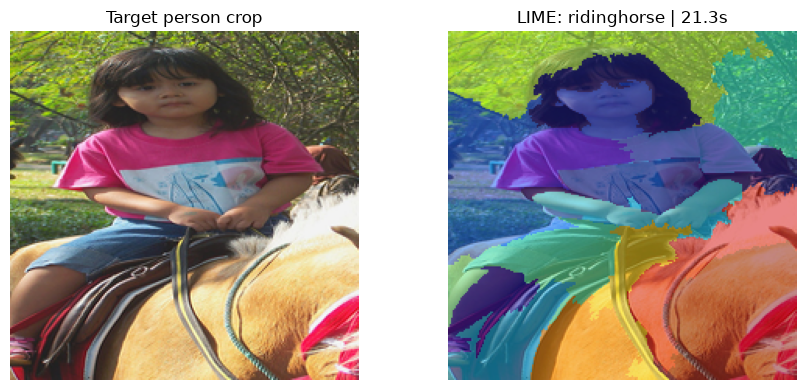

আজকের pilot শেষ। ফলাফল: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820
প্রথমে এই ৪টি file দেখুন:
 - classifier_comparison_DEV.csv
 - xai_DEV_comparison.csv
 - heldout_classification.csv
 - xai_HELDOUT_comparison.csv
পুনরায় notebook চালালে cache থাকায় feature extraction দ্রুত হবে।


In [10]:

raw_input=keras.Input(shape=(SIZE,SIZE,3),dtype='float32',name='rgb_0_255')
if BEST_MODEL=='MobileNetV2':
    processed=keras.layers.Rescaling(1/127.5,offset=-1)(raw_input)
elif BEST_MODEL=='ResNet50':
    processed=raw_input[...,::-1]-np.array([103.939,116.779,123.68],dtype=np.float32)
else:
    processed=raw_input
feature_map=base(processed,training=False)
pooled=keras.layers.GlobalAveragePooling2D()(feature_map)
raw_output=head(pooled,training=False)
pipeline=keras.Model(raw_input,raw_output)
reference=np.array(X[ih[:min(3,len(ih))]],dtype=np.float32)
np.testing.assert_allclose(pipeline(reference,training=False).numpy(),predict_raw(reference),rtol=1e-4,atol=1e-5)
pipeline.save(RUN/'selected_classifier_RAW_RGB.keras')

def predict_and_explain(image_path,box,action=None):
    image=crop_person(image_path,box,MARGIN,SIZE).astype(np.float32)
    scores=predict_raw(image)[0]
    if action is not None and action not in CLASSES: raise ValueError('Unknown action: '+str(action))
    c=CLASSES.index(action) if action is not None else int(np.argmax(scores))
    started=time.perf_counter(); heat,extra=EXPLAINERS[BEST_XAI](image,c)
    seconds=time.perf_counter()-started
    table=pd.DataFrame(dict(action=CLASSES,score=scores,above_threshold=scores>=THRESHOLD))
    display(table.sort_values('score',ascending=False))
    fig,axes=plt.subplots(1,2,figsize=(9,4))
    axes[0].imshow(image.astype(np.uint8));axes[0].set_title('Target person crop')
    axes[1].imshow(image.astype(np.uint8))
    axes[1].imshow(heat/(heat.max()+1e-12),cmap='jet',alpha=.45,vmin=0,vmax=1)
    axes[1].set_title(f'{BEST_XAI}: {CLASSES[c]} | {seconds:.1f}s')
    for ax in axes:ax.axis('off')
    fig.tight_layout();fig.savefig(RUN/'selected_pipeline_demo.png',dpi=150);plt.show()
    return table,heat

demo=df.iloc[int(ih[0])]
demo_result=predict_and_explain(demo.image_path,[demo.xmin,demo.ymin,demo.xmax,demo.ymax])
for name in ['LIME','GradCAM','IntegratedGradients','Occlusion']:
    if name not in dev_xai_comparison.method.values: raise RuntimeError('An XAI method is missing.')

limitations = {
 'completed':['person-level multilabel loader','image-independent inner split',
   'three frozen-backbone classifier runs','four XAI methods on selected model',
   'development-only selection','held-out official validation reporting','selected prediction/explanation demo'],
 'pending':['repeated training seeds and confidence intervals','larger explanation benchmark including negatives and errors',
   'held-out LIME surrogate fidelity','explanation stability and parameter sensitivity',
   'alternative replacement baseline','random-ranking attribution baseline','model-randomisation sanity checks',
   'comprehensive runtime distributions','manuscript novelty assessment and reviewer response'],
 'not_demonstrated':['robot control','collision avoidance','human trust','real-time HRI'],
 'note':'Do not report this single-seed pilot as completion of every reviewer request.'}
(RUN/'experiment_status.json').write_text(json.dumps(limitations,indent=2),encoding='utf-8')
(RUN/'sources.txt').write_text('\n'.join([
 'VOC action policy, per-person ±1 labels: https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/voc2012/htmldoc/index.html (2.3, 2.8, 6, 10.1.5)',
 'VOC counts: https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/voc2012/dbstats.html',
 'LIME: https://arxiv.org/abs/1602.04938',
 'Grad-CAM: https://arxiv.org/abs/1610.02391',
 'Integrated Gradients: https://proceedings.mlr.press/v70/sundararajan17a.html',
 'Occlusion: https://arxiv.org/abs/1311.2901',
 'Deletion/insertion: https://arxiv.org/abs/1806.07421']),encoding='utf-8')
print('আজকের pilot শেষ। ফলাফল:',RUN)
print('প্রথমে এই ৪টি file দেখুন:')
for name in ['classifier_comparison_DEV.csv','xai_DEV_comparison.csv',
             'heldout_classification.csv','xai_HELDOUT_comparison.csv']:
    print(' -',name)
print('পুনরায় notebook চালালে cache থাকায় feature extraction দ্রুত হবে।')

# পরের ধাপ: একই split-এ আরও দুইবার training

আগের experiment শেষ। সেটির dataset, crops ও ImageNet features আবার তৈরি করার প্রয়োজন নেই।

এই notebook আগের seed-এর saved checkpoints রাখবে এবং seed **123 ও 2026** দিয়ে আরও দুইবার classifier head train করবে। মোট তিনটি seed-এর mean ও standard deviation দেবে।

**শুধু Cell 1-এ `SOURCE_RUN` path দিন। তারপর Cell 1 → Cell 2 → Cell 3 চালান।** আগের TensorFlow kernel/environment ব্যবহার করুন।

চারটি XAI method এই ধাপে আবার চালানো হয় না। পুরোনো ফলাফল overwrite হয় না। নতুন output আগের run folder-এর ভিতরে পৃথক folder-এ যাবে।

এটি training variability পরীক্ষা করে। একই held-out set আগেও দেখা হয়েছে; এখানে সেটি tuning বা নতুন winner বেছে নেওয়ার জন্য ব্যবহৃত হচ্ছে না।


## Cell 1: আগের result folder খুলুন


In [1]:

from pathlib import Path
from datetime import datetime
import json, hashlib, time, gc, sys, platform
import numpy as np
import pandas as pd
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import precision_recall_fscore_support, f1_score
from IPython.display import display

SOURCE_RUN = Path(r'D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820')
if not (SOURCE_RUN/'dataset_manifest.csv').is_file():
    raise FileNotFoundError('SOURCE_RUN-এ আগের dataset_manifest.csv নেই। আপনার আগের run folder-এর path দিন।')
cfg = json.loads((SOURCE_RUN/'config.json').read_text(encoding='utf-8'))
selection = json.loads((SOURCE_RUN/'selection.json').read_text(encoding='utf-8'))
CLASSES = list(selection['classes'])
MODELS = list(cfg['models'])
SOURCE_SEED = int(cfg['seed'])
SEEDS = list(dict.fromkeys([SOURCE_SEED, 123, 2026]))
if len(SEEDS) != 3:
    raise ValueError('এই notebook তিনটি আলাদা seed প্রত্যাশা করে। SEEDS-এ তিনটি পৃথক integer দিন।')
if tf.__version__ != cfg['tensorflow']:
    raise RuntimeError('আগের run-এর TensorFlow environment ব্যবহার করুন। Version বদলালে comparison-এ আরেকটি পরিবর্তন যুক্ত হবে।')
EPOCHS = int(cfg['epochs'])
CACHE = SOURCE_RUN.parent/'cache'
df = pd.read_csv(SOURCE_RUN/'dataset_manifest.csv', dtype={'image_id': str})
Y = df[CLASSES].to_numpy(dtype=np.float32)
IDX = {s: np.flatnonzero(df.split.eq(s).to_numpy()) for s in ['train','dev','heldout_official_val']}
if any(len(v) == 0 for v in IDX.values()): raise ValueError('আগের manifest-এ train/dev/heldout split পাওয়া যায়নি।')
image_sets = [set(df.iloc[ix].image_id) for ix in IDX.values()]
if any(image_sets[i] & image_sets[j] for i in range(3) for j in range(i)):
    raise ValueError('Manifest-এ image overlap পাওয়া গেছে।')
OUTPUT = SOURCE_RUN/('repeat_seeds_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
OUTPUT.mkdir(parents=True, exist_ok=False)
print('আগের run:', SOURCE_RUN)
print('আগের seed:', SOURCE_SEED, '| অতিরিক্ত seeds:', SEEDS[1:])
print('আজ শুধু classifier repeat হবে; চারটি XAI আবার চালানো হবে না।')
print('নতুন ফলাফল:', OUTPUT)

def voc_ap(y, score):
    y = np.asarray(y,dtype=int); score = np.asarray(score,dtype=float)
    if y.sum() == 0: return float('nan')
    order = np.argsort(-score,kind='mergesort')
    tp = np.cumsum(y[order] == 1); fp = np.cumsum(y[order] == 0)
    recall = tp/y.sum(); precision = tp/np.maximum(tp+fp,1)
    mr = np.r_[0.,recall,1.]; mp = np.r_[0.,precision,0.]
    mp = np.maximum.accumulate(mp[::-1])[::-1]
    ix = np.where(mr[1:] != mr[:-1])[0]
    return float(np.sum((mr[ix+1]-mr[ix])*mp[ix+1]))

def ap_vector(y,p):
    return np.array([voc_ap(y[:,c],p[:,c]) for c in range(len(CLASSES))])

def classification_metrics(y,p,threshold=.5):
    pred = (p>=threshold).astype(int)
    pr,re,f,_ = precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    return dict(mAP=float(np.nanmean(ap_vector(y,p))),macro_precision=float(pr),
        macro_recall=float(re),macro_F1=float(f),
        micro_F1=float(f1_score(y,pred,average='micro',zero_division=0)))

class DevMAP(keras.callbacks.Callback):
    def __init__(self,x,y): super().__init__(); self.x=x; self.y=y
    def on_epoch_end(self,epoch,logs=None):
        score = float(np.nanmean(ap_vector(self.y,self.model(self.x,training=False).numpy())))
        if logs is not None: logs['val_mAP'] = score
        print(f' | development mAP = {score:.4f}',flush=True)

আগের run: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820
আগের seed: 42 | অতিরিক্ত seeds: [123, 2026]
আজ শুধু classifier repeat হবে; চারটি XAI আবার চালানো হবে না।
নতুন ফলাফল: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\repeat_seeds_20261023_184525_651312


## Cell 2: অতিরিক্ত দুইটি seed চালান
আগের cached features যাচাই করে ব্যবহার করবে। Training-এর সময় কিছুক্ষণ output না এলেও অপেক্ষা করুন।


In [2]:

def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def find_verified_features(name):
    
    
    crop_key = hashlib.sha256((df.to_csv(index=False)+json.dumps(dict(
        size=cfg['size'], margin=cfg['margin'], resize='PIL BICUBIC',
        pillow=Image.__version__))).encode()).hexdigest()[:20]
    tag = hashlib.sha256((crop_key+name+cfg['tensorflow']+'imagenet_globalavg').encode()).hexdigest()[:20]
    expected = CACHE/f'features_{name}_{tag}.npy'
    candidates = ([expected] if expected.exists() else [])
    candidates += [p for p in sorted(CACHE.glob(f'features_{name}_*.npy')) if p != expected]
    original_head = keras.models.load_model(SOURCE_RUN/f'{name}_head.keras')
    saved_dev = np.load(SOURCE_RUN/f'{name}_dev_scores.npy')
    if saved_dev.shape != (len(IDX['dev']), len(CLASSES)):
        raise ValueError(f'{name}: saved development predictions-এর shape মিলছে না।')
    for candidate in candidates:
        F = np.load(candidate, mmap_mode='r')
        if F.shape != (len(df), int(original_head.input_shape[-1])): continue
        actual = original_head(np.array(F[IDX['dev']]), training=False).numpy()
        if np.allclose(actual, saved_dev, rtol=1e-4, atol=1e-6):
            print(name, ': cached features আগের development predictions-এর সঙ্গে মিলেছে।', flush=True)
            return candidate, original_head
    raise FileNotFoundError(f'{name}: verified cached features পাওয়া যায়নি। SOURCE_RUN-এর পাশে আগের cache folder রাখুন।')

feature_files, lineage, result_rows = {}, {}, []
for name in MODELS:
    keras.backend.clear_session(); gc.collect()
    feature_file, original_head = find_verified_features(name)
    feature_files[name] = str(feature_file)
    lineage[name] = dict(feature_file=str(feature_file), features_sha256=file_sha256(feature_file),
        original_head_sha256=file_sha256(SOURCE_RUN/f'{name}_head.keras'))
    F = np.load(feature_file, mmap_mode='r')
    xt, xd, xh = [np.array(F[IDX[s]], copy=True) for s in ['train','dev','heldout_official_val']]
    yt, yd, yh = [Y[IDX[s]] for s in ['train','dev','heldout_official_val']]
    for seed in SEEDS:
        started = time.perf_counter()
        if seed == SOURCE_SEED:
            head = original_head
            origin = 'reused_original_saved_checkpoint'
            epochs_run = None
        else:
            keras.utils.set_random_seed(seed)
            inputs = keras.Input(shape=(F.shape[1],))
            h = keras.layers.Dense(512, activation='relu')(inputs)
            h = keras.layers.Dropout(.5)(h)
            outputs = keras.layers.Dense(len(CLASSES), activation='sigmoid')(h)
            head = keras.Model(inputs, outputs)
            head.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
            hist = head.fit(xt, yt, validation_data=(xd,yd), epochs=EPOCHS, batch_size=64,
                callbacks=[DevMAP(xd,yd), keras.callbacks.EarlyStopping(
                    monitor='val_mAP', mode='max', patience=4, restore_best_weights=True)], verbose=0)
            head.save(OUTPUT/f'{name}_seed_{seed}_head.keras')
            pd.DataFrame(hist.history).to_csv(OUTPUT/f'{name}_seed_{seed}_history.csv', index=False)
            origin = 'new_head_training_from_same_cached_features'
            epochs_run = len(hist.history['loss'])
        dev = head(xd, training=False).numpy()
        threshold = float(max(np.arange(.05,.96,.05), key=lambda t:
            f1_score(yd, dev>=t, average='micro', zero_division=0)))
        heldout = head(xh, training=False).numpy()
        
        
        for split, y, p, t in [('dev',yd,dev,.5), ('heldout_official_val',yh,heldout,threshold)]:
            result_rows.append(dict(model=name, seed=seed, split=split,
                threshold=t, checkpoint_origin=origin, epochs_run=epochs_run,
                **classification_metrics(y,p,t)))
        np.savez_compressed(OUTPUT/f'{name}_seed_{seed}_scores.npz', dev=dev, heldout=heldout)
        ap = pd.DataFrame(dict(action=CLASSES,dev_AP=ap_vector(yd,dev),heldout_AP=ap_vector(yh,heldout)))
        ap.to_csv(OUTPUT/f'{name}_seed_{seed}_per_action_AP.csv',index=False)
        pd.DataFrame(result_rows).to_csv(OUTPUT/'repeated_training_raw.csv',index=False)
        print(f'{name} | seed {seed} | dev mAP {np.nanmean(ap_vector(yd,dev)):.4f} | '
              f'held-out mAP {np.nanmean(ap_vector(yh,heldout)):.4f} | {time.perf_counter()-started:.1f}s',flush=True)
    del original_head, head, F, xt, xd, xh
    gc.collect()

(OUTPUT/'feature_lineage.json').write_text(json.dumps(lineage,indent=2),encoding='utf-8')
print('Cell 2 শেষ। এখন Cell 3 চালান।')


MobileNetV2 : cached features আগের development predictions-এর সঙ্গে মিলেছে।
MobileNetV2 | seed 42 | dev mAP 0.7750 | held-out mAP 0.7735 | 0.1s
 | development mAP = 0.6932
 | development mAP = 0.7389
 | development mAP = 0.7600
 | development mAP = 0.7680
 | development mAP = 0.7709
 | development mAP = 0.7757
 | development mAP = 0.7756
 | development mAP = 0.7762
 | development mAP = 0.7779
 | development mAP = 0.7809
 | development mAP = 0.7763
 | development mAP = 0.7769
 | development mAP = 0.7778
 | development mAP = 0.7747
MobileNetV2 | seed 123 | dev mAP 0.7809 | held-out mAP 0.7771 | 5.1s
 | development mAP = 0.6854
 | development mAP = 0.7354
 | development mAP = 0.7515
 | development mAP = 0.7668
 | development mAP = 0.7739
 | development mAP = 0.7743
 | development mAP = 0.7767
 | development mAP = 0.7754
 | development mAP = 0.7776
 | development mAP = 0.7746
 | development mAP = 0.7755
 | development mAP = 0.7746
 | development mAP = 0.7807
 | development mAP = 0.7796
 |

## Cell 3: গড় ফলাফল ও ZIP তৈরি করুন
শেষে দেখানো `repeat_training_results.zip` upload করুন।


In [3]:

import zipfile
results = pd.DataFrame(result_rows)
grouped = results.groupby(['model','split'],sort=False)
numeric = grouped.agg(runs=('seed','nunique'),mAP_mean=('mAP','mean'),mAP_SD=('mAP','std'),
    macro_F1_mean=('macro_F1','mean'),macro_F1_SD=('macro_F1','std'),
    micro_F1_mean=('micro_F1','mean'),micro_F1_SD=('micro_F1','std')).reset_index()
if not numeric.runs.eq(3).all(): raise RuntimeError('সব model-এর তিনটি seed সম্পন্ন হয়নি।')
numeric.to_csv(OUTPUT/'repeated_training_summary_numeric.csv',index=False)
pretty = numeric[['model','split','runs']].copy()
for metric in ['mAP','macro_F1','micro_F1']:
    pretty[metric+' (%) mean +/- SD'] = [f'{100*m:.2f} +/- {100*s:.2f}'
        for m,s in zip(numeric[metric+'_mean'], numeric[metric+'_SD'])]
pretty.to_csv(OUTPUT/'repeated_training_summary.csv',index=False)
print('তিনটি seed-এর ফলাফল:'); display(pretty)
print('আগের নির্বাচিত pipeline:',selection['classifier'],'+',selection['xai'])
print('এই notebook held-out result দেখে ওই selection বদলায়নি।')

np.savez_compressed(OUTPUT/'evaluation_targets.npz',dev_y=Y[IDX['dev']],heldout_y=Y[IDX['heldout_official_val']],
    dev_image_id=df.iloc[IDX['dev']].image_id.to_numpy(dtype=str),
    heldout_image_id=df.iloc[IDX['heldout_official_val']].image_id.to_numpy(dtype=str),
    classes=np.array(CLASSES,dtype=str))
report=dict(source_run=str(SOURCE_RUN),source_seed=SOURCE_SEED,seeds=SEEDS,
    dataset_split='unchanged original manifest; grouped by source image',
    training='frozen ImageNet features; Dense512 ReLU; dropout0.5; sigmoid10; Adam1e-3; BCE',
    augmentation='none, matching the source pilot',
    checkpoint_selection='development mAP; early stopping patience4',
    dev_F1_threshold=0.5,heldout_F1_threshold='global threshold selected on development data for each model/seed',
    original_selection_unchanged=selection['classifier']+' + '+selection['xai'],
    interpretation='Mean and sample SD (ddof=1) over three training seeds; not a significance test or independent dataset replication.',
    heldout_previously_evaluated=True,
    pending=['XAI stability/sensitivity','larger XAI sample including negatives/errors',
             'additional explanation baselines and sanity checks','novelty and manuscript revision'],
    python=sys.version,tensorflow=tf.__version__,numpy=np.__version__,platform=platform.platform())
(OUTPUT/'repeat_protocol.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
archive=OUTPUT/'repeat_training_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT.iterdir()):
        if p.suffix in ['.csv','.json','.npz']: z.write(p,arcname=p.name)
print('পরের ধাপ শেষ। এই ZIP ফাইলটি দিন:',archive)
print('মূল checkpoints এবং আগের XAI ফলাফল পরিবর্তন করা হয়নি।')

তিনটি seed-এর ফলাফল:


,model,split,runs,mAP (%) mean +/- SD,macro_F1 (%) mean +/- SD,micro_F1 (%) mean +/- SD
0,MobileNetV2,dev,3,77.88 +/- 0.34,65.84 +/- 1.87,67.03 +/- 1.18
1,MobileNetV2,heldout_official_val,3,77.46 +/- 0.21,70.44 +/- 0.51,70.69 +/- 0.66
2,ResNet50,dev,3,79.08 +/- 0.11,66.56 +/- 1.43,67.53 +/- 1.25
3,ResNet50,heldout_official_val,3,78.90 +/- 0.39,71.60 +/- 0.29,71.87 +/- 0.77
4,EfficientNetB0,dev,3,82.85 +/- 0.22,73.73 +/- 0.88,74.63 +/- 0.95
5,EfficientNetB0,heldout_official_val,3,82.06 +/- 0.10,76.18 +/- 0.31,76.61 +/- 0.13


আগের নির্বাচিত pipeline: EfficientNetB0 + LIME
এই notebook held-out result দেখে ওই selection বদলায়নি।
পরের ধাপ শেষ। এই ZIP ফাইলটি দিন: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\repeat_seeds_20261023_184525_651312\repeat_training_results.zip
মূল checkpoints এবং আগের XAI ফলাফল পরিবর্তন করা হয়নি।


# পরের ধাপ: IG-এর হিসাব এবং LIME-এর নির্ভরযোগ্যতা যাচাই

বড় XAI benchmark সম্পন্ন হয়েছে। **Grad-CAM-এর গড় deletion/insertion ফল সেরা**, কিন্তু আগের 32-step IG-এর completeness error বেশ বড়। সেই IG result চূড়ান্ত বলার আগে numerical check প্রয়োজন।

**Cell 1-এ `SOURCE_RUN` দেখুন। আগের TensorFlow kernel-এ Cell 1 → 2 → 3 → 4 চালান।**

- Development split থেকে প্রতি action-এর ১টি করে মোট ১০টি আলাদা image নেওয়া হবে। এটি ছোট diagnostic sample।
- Cell 2 একই IG path-এ 32/64/128/256/512 steps-এর error ও পরের finer grid-এর map-এর মিল দেখবে। একই gradient pass পুনর্ব্যবহার করবে।
- Cell 3 LIME-এর ৩টি random seed ও 200/400/800 samples তুলনা করবে। Training-এ ব্যবহার হয়নি এমন ২০০টি নতুন mask-এ surrogate-এর prediction মেলাবে।
- Cell 4 ফলাফলের ZIP তৈরি করবে।

এই ধাপে model training বা নতুন winner নির্বাচন নেই। এটি আগে দেখা held-out sample দিয়ে hyperparameter বাছাই করে না। মূল ফলাফল পৃথক থাকবে। প্রতি diagnostic case শেষে checkpoint থাকবে; বন্ধ হলে Cell 1 থেকে চালালে সম্পন্ন case ব্যবহার করবে।

`xai_reliability_results.zip` upload করুন। IG-এর কম error হলেই ব্যাখ্যা সঠিক প্রমাণ হয় না; map-এর convergence-ও দেখতে হবে।


In [1]:
from pathlib import Path
import json, hashlib, time, sys, platform, gc, io, contextlib, zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from skimage.segmentation import slic
from lime import lime_image
from IPython.display import display
SOURCE_RUN = Path('D:\\LIME\\VOC_XAI_Quick_Run\\run_20261023_165820')
required = ['config.json', 'selection.json', 'dataset_manifest.csv', 'heldout_predictions.csv', 'selected_classifier_RAW_RGB.keras']
missing = [n for n in required if not (SOURCE_RUN / n).is_file()]
if missing:
    raise FileNotFoundError('SOURCE_RUN ঠিক করুন। পাওয়া যায়নি: ' + ', '.join(missing))
cfg = json.loads((SOURCE_RUN / 'config.json').read_text(encoding='utf-8'))
selection = json.loads((SOURCE_RUN / 'selection.json').read_text(encoding='utf-8'))
if tf.__version__ != cfg['tensorflow']:
    raise RuntimeError('আগের experiment-এর TensorFlow kernel/environment ব্যবহার করুন।')
CLASSES = list(selection['classes'])
BEST_MODEL = str(selection['classifier'])
THRESHOLD = float(selection['threshold'])
SEED = int(cfg['seed'])
SIZE = int(cfg['size'])
BATCH = int(cfg['batch'])
LIME_SAMPLES = int(cfg['lime_samples'])
IG_STEPS = int(cfg['ig_steps'])
PATCH = int(cfg.get('patch', 32))
CACHE = SOURCE_RUN.parent / 'cache'
df = pd.read_csv(SOURCE_RUN / 'dataset_manifest.csv', dtype={'image_id': str})
Y = df[CLASSES].to_numpy(dtype=np.float32)
if not set(np.unique(Y)).issubset({0, 1}):
    raise ValueError('Manifest-এ অজানা label পাওয়া গেছে।')
IDX = {s: np.flatnonzero(df.split.eq(s).to_numpy()) for s in ['train', 'dev', 'heldout_official_val']}
image_sets = [set(df.iloc[ix].image_id) for ix in IDX.values()]
if any((image_sets[i] & image_sets[j] for i in range(3) for j in range(i))):
    raise ValueError('Source image overlap পাওয়া গেছে।')
held = pd.read_csv(SOURCE_RUN / 'heldout_predictions.csv', dtype={'image_id': str})
reference = df.iloc[IDX['heldout_official_val']]
if len(held) != len(reference) or not np.array_equal(held[['image_id', 'person_id']].to_numpy(), reference[['image_id', 'person_id']].to_numpy()):
    raise ValueError('Held-out predictions এবং manifest-এর row order মিলছে না।')
np.testing.assert_array_equal(held[CLASSES].to_numpy(), Y[IDX['heldout_official_val']])
held_scores = held[['score_' + c for c in CLASSES]].to_numpy(dtype=np.float32)
if not np.isfinite(held_scores).all() or np.any((held_scores < 0) | (held_scores > 1)):
    raise ValueError('Saved scores সঠিক নয়।')
pipeline = keras.models.load_model(SOURCE_RUN / 'selected_classifier_RAW_RGB.keras', compile=False)
nested = [layer for layer in pipeline.layers if isinstance(layer, keras.Model)]
backbones = [m for m in nested if len(m.output_shape) == 4]
heads = [m for m in nested if len(m.output_shape) == 2 and m.output_shape[-1] == len(CLASSES)]
if len(backbones) != 1 or len(heads) != 1:
    raise RuntimeError('Saved classifier-এর backbone/head চেনা যায়নি।')
base, head = (backbones[0], heads[0])
if BEST_MODEL == 'MobileNetV2':
    prep = keras.applications.mobilenet_v2.preprocess_input
elif BEST_MODEL == 'ResNet50':
    prep = keras.applications.resnet50.preprocess_input
elif BEST_MODEL == 'EfficientNetB0':
    prep = keras.applications.efficientnet.preprocess_input
else:
    raise ValueError('Unknown classifier: ' + BEST_MODEL)
keras.utils.set_random_seed(SEED)
for device in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(device, True)
    except RuntimeError:
        pass
print('আগের model:', BEST_MODEL, '| original training seed:', SEED)
print('মূল XAI selection:', selection['xai'], '| threshold:', round(THRESHOLD, 2))
print('এখন Cell 2 চালান।')


from itertools import combinations
from importlib.metadata import version as package_version
from scipy.stats import spearmanr
from sklearn.metrics import r2_score, mean_absolute_error, pairwise_distances

DEV_PER_CLASS = 1
PAIR_SEED = 20261025
IG_GRID = [32,64,128,256,512]
IG_ATOL = .01
IG_RTOL = .05
TEST_MASKS = 200
TOP_FRACTION = .20
LIME_REPEAT_SEEDS = [SEED,123,2026]
LIME_SAMPLE_COUNTS = [LIME_SAMPLES//2,LIME_SAMPLES,LIME_SAMPLES*2]
CODE_VERSION = 'xai_reliability_v1.0'
EXPECTED_SOURCE = {'config.json': '392661662087f04aae4f3c9cc6ee48cdcd4d1ab31d09d7ab1f212ff59d5a5b93', 'selection.json': '51a2c06c63f1db8a6ded7ef691ce5db20db9c84c7c3a73dfc226eb32a4a0742b', 'dataset_manifest.csv': '8198d9618738fd0017a0ab089cbf8ef77cf44a5c79970052b50b77beeee72179', 'selected_classifier_RAW_RGB.keras': '8c7af7cd6a8f64b2559a0fc97cc870e7a6f9f339a84e80ec68cb293e70e07bb9'}
EXPECTED_CROP_SHA256 = 'bf599cedd1eb41de1e0e52e6de971531b6b230f82b26cbcc431182cb6b1450fc'

def predict_raw(images):
    images = np.asarray(images,dtype=np.float32)
    if images.ndim == 3: images = images[None]
    result = []
    for i in range(0,len(images),BATCH):
        z = tf.convert_to_tensor(images[i:i+BATCH])
        maps = base(prep(z),training=False)
        result.append(head(tf.reduce_mean(maps,axis=(1,2)),training=False).numpy())
    return np.concatenate(result,axis=0)

def positive_map(a):
    a = np.maximum(np.asarray(a,dtype=np.float32),0)
    if not np.isfinite(a).all(): raise ValueError('Explanation contains NaN or infinity.')
    return a

def patch_boxes():
    return [(y,min(y+PATCH,SIZE),x,min(x+PATCH,SIZE))
            for y in range(0,SIZE,PATCH) for x in range(0,SIZE,PATCH)]

def file_sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def atomic_json(path,value):
    temporary=Path(str(path)+'.partial')
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
    temporary.replace(path)

def verified_crop_cache():
    crop_key=hashlib.sha256((df.to_csv(index=False)+json.dumps(dict(size=SIZE,
        margin=cfg['margin'],resize='PIL BICUBIC',pillow=Image.__version__))).encode()).hexdigest()[:20]
    expected=CACHE/f'crops_{crop_key}.npy'
    candidates=([expected] if expected.exists() else [])
    candidates += [p for p in sorted(CACHE.glob('crops_*.npy')) if p!=expected]
    
    
    rng=np.random.default_rng(PAIR_SEED)
    checks=[];targets=[]
    for split in ['dev','heldout_official_val']:
        local=np.sort(rng.choice(len(IDX[split]),min(12,len(IDX[split])),replace=False))
        checks.extend(IDX[split][local].tolist())
        if split=='dev':
            saved=np.load(SOURCE_RUN/f'{BEST_MODEL}_dev_scores.npy')
            targets.extend(saved[local].tolist())
        else: targets.extend(held_scores[local].tolist())
    for path in candidates:
        crops=np.load(path,mmap_mode='r')
        if crops.shape!=(len(df),SIZE,SIZE,3) or crops.dtype!=np.uint8: continue
        images=np.array(crops[checks],dtype=np.float32)
        actual=predict_raw(images)
        if np.allclose(actual,np.asarray(targets),rtol=1e-4,atol=1e-5):
            np.testing.assert_allclose(pipeline(images,training=False).numpy(),actual,rtol=1e-4,atol=1e-5)
            print('Crop cache ও saved predictions মিলেছে:',path.name,flush=True)
            return path,crops
    raise FileNotFoundError('সঠিক crop cache পাওয়া যায়নি। আগের run-এর পাশের cache folder রাখুন।')

def safe_map_comparison(first,second):
    boxes=patch_boxes()
    a=np.array([first[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes],dtype=float)
    b=np.array([second[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes],dtype=float)
    empty_a=not np.any(a>0);empty_b=not np.any(b>0)
    if empty_a or empty_b:
        return dict(spearman=None,top_patch_Jaccard=None,degenerate_map=True)
    
    k=max(1,int(np.ceil(TOP_FRACTION*len(boxes))))
    aa=np.argsort(-a,kind='mergesort');bb=np.argsort(-b,kind='mergesort')
    sa=set(aa[a[aa]>0][:k]);sb=set(bb[b[bb]>0][:k])
    rho=None
    if np.ptp(a)>0 and np.ptp(b)>0:
        value=float(spearmanr(a,b).statistic)
        if np.isfinite(value):rho=value
    return dict(spearman=rho,top_patch_Jaccard=float(len(sa&sb)/len(sa|sb)),degenerate_map=False)

for filename,digest in EXPECTED_SOURCE.items():
    if file_sha256(SOURCE_RUN/filename)!=digest:
        raise RuntimeError('Source run আপলোড করা ফলাফলের সঙ্গে মিলছে না: '+filename)
CROP_FILE,X=verified_crop_cache()
crop_digest=file_sha256(CROP_FILE)
if EXPECTED_CROP_SHA256 and crop_digest!=EXPECTED_CROP_SHA256: raise RuntimeError('Source crop file বদলেছে।')
dev_scores=np.load(SOURCE_RUN/f'{BEST_MODEL}_dev_scores.npy')
if dev_scores.shape!=(len(IDX['dev']),len(CLASSES)):raise ValueError('Development score shape mismatch.')
rng=np.random.default_rng(PAIR_SEED);used=set();case_rows=[]
for c,action in enumerate(CLASSES):
    available=np.flatnonzero(Y[IDX['dev'],c]>0);rng.shuffle(available);chosen=0
    for local in available:
        i=int(IDX['dev'][local]);r=df.iloc[i]
        if str(r.image_id) in used:continue
        used.add(str(r.image_id));chosen+=1
        case_rows.append(dict(case_id=f'd{len(case_rows):03d}',record_index=i,image_id=str(r.image_id),
            person_id=int(r.person_id),class_index=c,action=action,score=float(dev_scores[local,c])))
        if chosen==DEV_PER_CLASS:break
    if chosen!=DEV_PER_CLASS:raise RuntimeError('প্রয়োজনীয় development case পাওয়া যায়নি: '+action)
CASES=pd.DataFrame(case_rows)
assert not CASES.image_id.duplicated().any()
if len(set(LIME_REPEAT_SEEDS))!=3:raise ValueError('তিনটি আলাদা LIME seed দরকার।')
if not all(max(IG_GRID)%n==0 for n in IG_GRID):raise ValueError('IG grids must be nested.')
protocol=dict(code_version=CODE_VERSION,source_run=str(SOURCE_RUN),
    source_hashes=EXPECTED_SOURCE,crop_sha256=crop_digest,classifier=BEST_MODEL,training_seed=SEED,
    original_selection_unchanged=BEST_MODEL+' + '+selection['xai'],
    cases_per_action=DEV_PER_CLASS,case_seed=PAIR_SEED,split='development only; no heldout tuning or new winner selection',
    IG=dict(grids=IG_GRID,baseline='raw RGB black',target='original sigmoid action score',
        integration='nested trapezoidal grids reuse a single finest-grid gradient pass; float64 accumulation',
        error='abs(sum(SIGNED attributions) - (F(image)-F(black)))',
        numerical_gate='error <= atol + rtol*abs(F(image)-F(black)); a declared diagnostic tolerance, not a universal standard',
        atol=IG_ATOL,rtol=IG_RTOL,map_comparison='positive map versus next finer grid; last grid has no finer reference'),
    LIME=dict(perturbation_seeds=LIME_REPEAT_SEEDS,sample_counts=LIME_SAMPLE_COUNTS,
        reference_samples=LIME_SAMPLES,reference_seed=SEED,kernel_width=.25,
        segmentation='fixed SLIC40, compactness10; same segments across all fits for each image',
        hide_color='black',test_masks=TEST_MASKS,test_seed_offset=1000000,
        fidelity='reserved Bernoulli(0.5) superpixel masks; disjoint from training masks of ALL settings; same test masks for every setting',
        scores='cosine-kernel-weighted R2 and MAE of unclipped signed linear surrogate versus fixed classifier',
        interpretation='reserved perturbations of DEVELOPMENT images; not untouched test images or semantic explanation ground truth'),
    stability=dict(unit='same fixed nonoverlapping patch grid as benchmark',top_fraction=TOP_FRACTION,
        metrics=['Spearman rank correlation','positive top-patch Jaccard'],
        zero_maps='undefined comparisons saved as null with degenerate_map=true; never counted as perfect stability'),
    caveats=['One positive development image per action by default: a small diagnostic sample.',
        'Completeness error is a numerical check; low error alone does not prove attribution correctness or map convergence.',
        'Repeatability under LIME random seeds is not robustness to arbitrary input changes.',
        'This notebook diagnoses IG integration settings; it does not retroactively validate the previous 32-step heldout IG ranking.'],
    tensorflow=tf.__version__,keras=keras.__version__,numpy=np.__version__,lime=package_version('lime'))
signature=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()[:12]
OUTPUT=SOURCE_RUN/f'xai_reliability_{signature}'
OUTPUT.mkdir(exist_ok=True)
for sub in ['ig_records','ig_maps','lime_records','lime_data']:(OUTPUT/sub).mkdir(exist_ok=True)
if (OUTPUT/'reliability_protocol.json').exists():
    if json.loads((OUTPUT/'reliability_protocol.json').read_text())!=protocol:raise RuntimeError('Existing protocol mismatch.')
else:atomic_json(OUTPUT/'reliability_protocol.json',protocol)
CASES.to_csv(OUTPUT/'development_cases.csv',index=False)
(OUTPUT/'sources.txt').write_text('\n'.join([
    'IG original paper: https://proceedings.mlr.press/v70/sundararajan17a.html',
    'IG integration implementation and approximation: https://www.tensorflow.org/tutorials/interpretability/integrated_gradients',
    'LIME source API and cosine kernel: https://github.com/marcotcr/lime/blob/master/lime/lime_image.py',
    'LIME paper: https://arxiv.org/abs/1602.04938',
    'The numeric gate and reserved-mask diagnostic are specified in reliability_protocol.json, not universal pass/fail standards.']),encoding='utf-8')
print('নতুন diagnostic cases:',len(CASES),'| development images only')
print('নতুন output:',OUTPUT)
print('এখন Cell 2 চালান।')

আগের model: EfficientNetB0 | original training seed: 42
মূল XAI selection: LIME | threshold: 0.4
এখন Cell 2 চালান।
Crop cache ও saved predictions মিলেছে: crops_fa51f5f1f134a0e8ac33.npy
নতুন diagnostic cases: 10 | development images only
নতুন output: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\xai_reliability_63af5fca9d5f
এখন Cell 2 চালান।


## Cell 2: IG numerical convergence
এই cell-এ সময় লাগবে। Progress দেখাবে।


In [2]:

def nested_ig_case(case):
    record_file=OUTPUT/'ig_records'/f'{case.case_id}.json'
    map_file=OUTPUT/'ig_maps'/f'{case.case_id}.npz'
    if record_file.exists() and map_file.exists():return json.loads(record_file.read_text())
    raw=np.array(X[int(case.record_index)],dtype=np.float32);c=int(case.class_index)
    p=float(predict_raw(raw)[0,c]);p0=float(predict_raw(np.zeros_like(raw))[0,c])
    if not np.isclose(p,case.score,rtol=1e-4,atol=1e-5):raise RuntimeError('Development prediction mismatch.')
    maximum=max(IG_GRID)
    sums={n:np.zeros_like(raw,dtype=np.float64) for n in IG_GRID}
    started=time.perf_counter()
    for start in range(0,maximum+1,BATCH):
        js=np.arange(start,min(start+BATCH,maximum+1),dtype=int)
        alpha=(js/maximum).astype(np.float32)
        z=tf.convert_to_tensor(alpha[:,None,None,None]*raw[None])
        with tf.GradientTape() as tape:
            tape.watch(z)
            maps=base(prep(z),training=False)
            target=head(tf.reduce_mean(maps,axis=(1,2)),training=False)[:,c]
        gradient=tape.gradient(target,z)
        if gradient is None:raise RuntimeError('IG gradient পাওয়া যায়নি।')
        g=gradient.numpy()
        if not np.isfinite(g).all():raise ValueError('Nonfinite IG gradient.')
        for offset,j in enumerate(js):
            for n in IG_GRID:
                if j%(maximum//n)==0:sums[n]+=(.5 if j in (0,maximum) else 1.)*g[offset].astype(np.float64)
        if start%(BATCH*8)==0 or js[-1]==maximum:
            print(f'IG {case.action}: gradients {int(js[-1])+1}/{maximum+1}',flush=True)
    seconds=time.perf_counter()-started
    signed={n:((raw.astype(np.float64)*sums[n]/n).sum(axis=-1)) for n in IG_GRID}
    rows=[];delta=p-p0;tolerance=IG_ATOL+IG_RTOL*abs(delta)
    for k,n in enumerate(IG_GRID):
        total=float(signed[n].sum(dtype=np.float64));error=abs(total-delta)
        finer=IG_GRID[k+1] if k+1<len(IG_GRID) else None
        comparison=(safe_map_comparison(np.maximum(signed[n],0),np.maximum(signed[finer],0)) if finer else
            dict(spearman=None,top_patch_Jaccard=None,degenerate_map=None))
        rows.append(dict(case._asdict(),steps=n,score=p,baseline_score=p0,score_difference=delta,
            signed_attribution_sum=total,completeness_absolute_error=error,
            relative_error_denominator=max(abs(delta),.01),
            completeness_scaled_error=error/max(abs(delta),.01),declared_tolerance=tolerance,
            passes_declared_error_gate=bool(error<=tolerance),comparison_steps=finer,
            next_grid_spearman=comparison['spearman'],next_grid_top_patch_Jaccard=comparison['top_patch_Jaccard'],
            comparison_degenerate=comparison['degenerate_map'],
            finest_grid_gradient_pass_seconds=seconds,gradient_points_computed=maximum+1))
    partial=Path(str(map_file)+'.partial')
    with partial.open('wb') as f:np.savez_compressed(f,**{f'signed_{n}':a.astype(np.float32) for n,a in signed.items()})
    partial.replace(map_file);atomic_json(record_file,rows)
    return rows

for number,case in enumerate(CASES.itertuples(index=False),1):
    rows=nested_ig_case(case)
    print(f'IG case {number}/{len(CASES)} শেষ | '+', '.join(f'{r["steps"]}: error={r["completeness_absolute_error"]:.4f}' for r in rows),flush=True)
print('IG diagnostic শেষ। এখন Cell 3 চালান।')

IG jumping: gradients 16/513
IG jumping: gradients 144/513
IG jumping: gradients 272/513
IG jumping: gradients 400/513
IG jumping: gradients 513/513
IG case 1/10 শেষ | 32: error=0.0744, 64: error=0.0330, 128: error=0.0022, 256: error=0.0020, 512: error=0.0000
IG phoning: gradients 16/513
IG phoning: gradients 144/513
IG phoning: gradients 272/513
IG phoning: gradients 400/513
IG phoning: gradients 513/513
IG case 2/10 শেষ | 32: error=0.3019, 64: error=0.1642, 128: error=0.0102, 256: error=0.0125, 512: error=0.0024
IG playinginstrument: gradients 16/513
IG playinginstrument: gradients 144/513
IG playinginstrument: gradients 272/513
IG playinginstrument: gradients 400/513
IG playinginstrument: gradients 513/513
IG case 3/10 শেষ | 32: error=0.2471, 64: error=0.0189, 128: error=0.0085, 256: error=0.0044, 512: error=0.0015
IG reading: gradients 16/513
IG reading: gradients 144/513
IG reading: gradients 272/513
IG reading: gradients 400/513
IG reading: gradients 513/513
IG case 4/10 শেষ | 32

## Cell 3: LIME repeatability ও নতুন masks


In [3]:

class RecordedLimeImageExplainer(lime_image.LimeImageExplainer):
    def data_labels(self,*args,**kwargs):
        data,labels=super().data_labels(*args,**kwargs)
        self.training_masks=data.copy()
        return data,labels

def lime_setting_id(samples,seed):return f'n{samples}_s{seed}'

def fit_lime_setting(image,c,segments,samples,seed):
    def binary_predict(images):
        p=predict_raw(images)[:,c]
        return np.c_[1-p,p]
    explainer=RecordedLimeImageExplainer(kernel_width=.25,random_state=seed)
    started=time.perf_counter()
    with contextlib.redirect_stderr(io.StringIO()):
        exp=explainer.explain_instance(image,binary_predict,labels=(1,),top_labels=None,
            hide_color=0,num_features=100000,num_samples=samples,batch_size=BATCH,
            segmentation_fn=lambda _:segments,random_seed=seed)
    elapsed=time.perf_counter()-started
    k=len(np.unique(segments));weights=np.zeros(k,dtype=np.float64)
    for feature,value in exp.local_exp[1]:weights[int(feature)]=float(value)
    heat=np.maximum(weights[segments],0).astype(np.float32)
    return dict(weights=weights,intercept=float(exp.intercept[1]),heatmap=heat,
        training_masks=explainer.training_masks.astype(np.uint8),
        in_sample_R2=float(exp.score),explanation_seconds=elapsed)

def reserved_masks(k,training,seed):
    rng=np.random.default_rng(seed)
    excluded={row.tobytes() for masks in training for row in np.asarray(masks,dtype=np.uint8)}
    held=[];seen=set()
    for attempt in range(100):
        for row in rng.integers(0,2,size=(max(TEST_MASKS,64),k),dtype=np.uint8):
            key=row.tobytes()
            if key in excluded or key in seen:continue
            seen.add(key);held.append(row)
            if len(held)==TEST_MASKS:return np.stack(held)
    raise RuntimeError('যথেষ্ট unseen masks পাওয়া যায়নি; superpixel count খুব কম হতে পারে।')

def predict_reserved(image,c,segments,masks):
    result=[]
    for start in range(0,len(masks),BATCH):
        keep=masks[start:start+BATCH][:,segments]
        perturbed=image[None]*keep[:,:,:,None]
        result.extend(predict_raw(perturbed)[:,c].tolist())
    return np.asarray(result,dtype=np.float64)

def lime_case(case):
    record_file=OUTPUT/'lime_records'/f'{case.case_id}.json'
    data_file=OUTPUT/'lime_data'/f'{case.case_id}.npz'
    if record_file.exists() and data_file.exists():return json.loads(record_file.read_text())
    image=np.array(X[int(case.record_index)],dtype=np.float32);c=int(case.class_index)
    actual=float(predict_raw(image)[0,c])
    if not np.isclose(actual,case.score,rtol=1e-4,atol=1e-5):raise RuntimeError('Development prediction mismatch.')
    segments=slic(image/255.,n_segments=40,compactness=10,start_label=0,channel_axis=-1)
    if not np.array_equal(np.unique(segments),np.arange(len(np.unique(segments)))):raise ValueError('Noncontiguous segments.')
    settings=list(dict.fromkeys([(LIME_SAMPLES,s) for s in LIME_REPEAT_SEEDS]+[(n,SEED) for n in LIME_SAMPLE_COUNTS]))
    fits={}
    for samples,seed in settings:
        key=lime_setting_id(samples,seed)
        fits[key]=fit_lime_setting(image,c,segments,samples,seed)
        print(f'LIME {case.action} | samples {samples} | seed {seed} | {fits[key]["explanation_seconds"]:.1f}s',flush=True)
    masks=reserved_masks(len(np.unique(segments)),[f['training_masks'] for f in fits.values()],
        PAIR_SEED+1000000+int(case.record_index)*len(CLASSES)+c)
    truth=predict_reserved(image,c,segments,masks)
    distances=pairwise_distances(masks.astype(float),np.ones((1,masks.shape[1])),metric='cosine').ravel()
    kernel=np.sqrt(np.exp(-(distances**2)/(.25**2)))
    weighted_mean=float(np.average(truth,weights=kernel))
    weighted_variance=float(np.average((truth-weighted_mean)**2,weights=kernel))
    fidelity=[];saved=dict(test_masks=masks,test_classifier_scores=truth,test_kernel_weights=kernel,segments=segments)
    for samples,seed in settings:
        key=lime_setting_id(samples,seed);fit=fits[key]
        surrogate=fit['intercept']+masks@fit['weights']
        r2=(float(r2_score(truth,surrogate,sample_weight=kernel,force_finite=False)) if weighted_variance>1e-12 else None)
        if r2 is not None and not np.isfinite(r2):r2=None
        fidelity.append(dict(**case._asdict(),samples=samples,perturbation_seed=seed,
            in_sample_R2=fit['in_sample_R2'],reserved_mask_weighted_R2=r2,
            reserved_mask_weighted_MAE=float(mean_absolute_error(truth,surrogate,sample_weight=kernel)),
            reserved_mask_target_variance=weighted_variance,
            surrogate_outside_unit_interval_fraction=float(np.mean((surrogate<0)|(surrogate>1))),
            explanation_seconds=fit['explanation_seconds'],all_zero_map=bool(fit['heatmap'].max()<=0),
            superpixels=len(np.unique(segments)),test_masks=len(masks)))
        saved['weights_'+key]=fit['weights'];saved['intercept_'+key]=np.array(fit['intercept'])
        saved['train_masks_'+key]=fit['training_masks'];saved['positive_map_'+key]=fit['heatmap']
    stability=[]
    for first,second in combinations(LIME_REPEAT_SEEDS,2):
        a=fits[lime_setting_id(LIME_SAMPLES,first)]['heatmap'];b=fits[lime_setting_id(LIME_SAMPLES,second)]['heatmap']
        stability.append(dict(**case._asdict(),comparison='perturbation_seed',samples_a=LIME_SAMPLES,samples_b=LIME_SAMPLES,
            seed_a=first,seed_b=second,**safe_map_comparison(a,b)))
    reference=fits[lime_setting_id(LIME_SAMPLES,SEED)]['heatmap']
    for samples in LIME_SAMPLE_COUNTS:
        if samples==LIME_SAMPLES:continue
        heat=fits[lime_setting_id(samples,SEED)]['heatmap']
        stability.append(dict(**case._asdict(),comparison='number_of_samples',samples_a=LIME_SAMPLES,samples_b=samples,
            seed_a=SEED,seed_b=SEED,**safe_map_comparison(reference,heat)))
    result=dict(fidelity=fidelity,stability=stability)
    partial=Path(str(data_file)+'.partial')
    with partial.open('wb') as f:np.savez_compressed(f,**saved)
    partial.replace(data_file);atomic_json(record_file,result)
    return result

for number,case in enumerate(CASES.itertuples(index=False),1):
    _result=lime_case(case)
    print(f'LIME case {number}/{len(CASES)} শেষ।',flush=True)
print('এখন Cell 4 চালান।')

  0%|          | 0/400 [00:00<?, ?it/s]

LIME jumping | samples 400 | seed 42 | 22.3s


  0%|          | 0/400 [00:00<?, ?it/s]

LIME jumping | samples 400 | seed 123 | 21.6s


  0%|          | 0/400 [00:00<?, ?it/s]

...

LIME walking | samples 400 | seed 2026 | 21.5s


  0%|          | 0/200 [00:00<?, ?it/s]

LIME walking | samples 200 | seed 42 | 10.8s


  0%|          | 0/800 [00:00<?, ?it/s]

LIME walking | samples 800 | seed 42 | 42.7s
LIME case 10/10 শেষ।
এখন Cell 4 চালান।


## Cell 4: ZIP তৈরি করুন


In [4]:

ig_rows=[];fidelity_rows=[];stability_rows=[]
for case in CASES.itertuples(index=False):
    ip=OUTPUT/'ig_records'/f'{case.case_id}.json';lp=OUTPUT/'lime_records'/f'{case.case_id}.json'
    if not ip.exists() or not lp.exists():raise RuntimeError('Cell 2 বা Cell 3 অসম্পূর্ণ: '+case.case_id)
    ig_rows+=json.loads(ip.read_text())
    r=json.loads(lp.read_text());fidelity_rows+=r['fidelity'];stability_rows+=r['stability']
ig_table=pd.DataFrame(ig_rows);fidelity=pd.DataFrame(fidelity_rows);stability=pd.DataFrame(stability_rows)
if len(ig_table)!=len(CASES)*len(IG_GRID):raise RuntimeError('Incomplete IG rows.')
if fidelity.duplicated(['case_id','samples','perturbation_seed']).any():raise RuntimeError('Duplicate LIME settings.')
ig_table.to_csv(OUTPUT/'IG_convergence_raw.csv',index=False)
fidelity.to_csv(OUTPUT/'LIME_fidelity_raw.csv',index=False)
stability.to_csv(OUTPUT/'LIME_stability_raw.csv',index=False)
ig_summary=ig_table.groupby('steps').agg(cases=('case_id','nunique'),
    error_mean=('completeness_absolute_error','mean'),error_median=('completeness_absolute_error','median'),
    error_max=('completeness_absolute_error','max'),declared_gate_pass_fraction=('passes_declared_error_gate','mean'),
    next_grid_spearman_mean=('next_grid_spearman','mean'),
    next_grid_top_patch_Jaccard_mean=('next_grid_top_patch_Jaccard','mean')).reset_index()
ig_summary.to_csv(OUTPUT/'IG_convergence_summary.csv',index=False)
fidelity_summary=fidelity.groupby(['samples','perturbation_seed']).agg(cases=('case_id','nunique'),
    in_sample_R2_mean=('in_sample_R2','mean'),reserved_R2_valid_cases=('reserved_mask_weighted_R2','count'),
    reserved_R2_mean=('reserved_mask_weighted_R2','mean'),reserved_R2_median=('reserved_mask_weighted_R2','median'),
    reserved_MAE_mean=('reserved_mask_weighted_MAE','mean'),zero_map_fraction=('all_zero_map','mean'),
    explanation_seconds_mean=('explanation_seconds','mean')).reset_index()
fidelity_summary.to_csv(OUTPUT/'LIME_fidelity_summary.csv',index=False)
stability_summary=stability.groupby(['comparison','samples_a','samples_b','seed_a','seed_b']).agg(
    cases=('case_id','nunique'),spearman_valid_cases=('spearman','count'),spearman_mean=('spearman','mean'),
    Jaccard_valid_cases=('top_patch_Jaccard','count'),Jaccard_mean=('top_patch_Jaccard','mean'),
    degenerate_fraction=('degenerate_map','mean')).reset_index()
stability_summary.to_csv(OUTPUT/'LIME_stability_summary.csv',index=False)
status=dict(completed=['nested-grid IG convergence diagnostic on fixed development sample',
    'LIME random-seed repeatability and sample-count sensitivity on fixed SLIC segments',
    'reserved-mask LIME fidelity with masks excluded from all fitted neighborhoods'],
    not_yet_claimed=['previous 32-step heldout IG results are numerically reliable',
        'low completeness error proves correct saliency maps','new best deployment method'],
    pending=['assess these diagnostic results and resolve any failed numerical check',
        'recompute heldout IG comparison if a numerically adequate setting is established',
        'model parameter randomisation sanity checks',
        'manuscript novelty assessment and reviewer-specific revisions'],
    selection_unchanged=BEST_MODEL+' + '+selection['xai'],python=sys.version,platform=platform.platform())
atomic_json(OUTPUT/'reliability_status.json',status)
archive=OUTPUT/'xai_reliability_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT.iterdir()):
        if p.is_file() and p.suffix in ['.csv','.json','.txt']:z.write(p,arcname=p.name)
    
    for p in sorted((OUTPUT/'lime_data').glob('*.npz')):z.write(p,arcname='lime_data/'+p.name)
print('IG numerical diagnostic:');display(ig_summary)
print('LIME reserved-mask fidelity:');display(fidelity_summary)
print('LIME repeatability/sensitivity:');display(stability_summary)
print('এই ZIP upload করুন:',archive)
print('এই ফলাফল দেখে পরের সংশোধন ঠিক করব। আগের selection:',BEST_MODEL,'+',selection['xai'])

IG numerical diagnostic:


,steps,cases,error_mean,error_median,error_max,declared_gate_pass_fraction,next_grid_spearman_mean,next_grid_top_patch_Jaccard_mean
0,32,10,0.222147,0.255882,0.488507,0.0,0.994102,0.875758
1,64,10,0.080106,0.081101,0.164210,0.3,0.999031,0.981818
2,128,10,0.021993,0.012999,0.052748,0.7,0.999796,1.000000
3,256,10,0.004210,0.003777,0.012539,1.0,0.999918,1.000000
4,512,10,0.002372,0.001213,0.006691,1.0,NaN,NaN


LIME reserved-mask fidelity:


,samples,perturbation_seed,cases,in_sample_R2_mean,reserved_R2_valid_cases,reserved_R2_mean,reserved_R2_median,reserved_MAE_mean,zero_map_fraction,explanation_seconds_mean
0,200,42,10,0.566085,10,0.457670,0.530137,0.101659,0.0,10.853344
1,400,42,10,0.540094,10,0.502625,0.548718,0.098385,0.0,21.591383
2,400,123,10,0.546259,10,0.483524,0.518967,0.100568,0.0,21.447886
3,400,2026,10,0.544519,10,0.491648,0.531121,0.098843,0.0,21.434657
4,800,42,10,0.531577,10,0.519040,0.569248,0.096890,0.0,42.837933


LIME repeatability/sensitivity:


,comparison,samples_a,samples_b,seed_a,seed_b,cases,spearman_valid_cases,spearman_mean,Jaccard_valid_cases,Jaccard_mean,degenerate_fraction
0,number_of_samples,400,200,42,42,10,10,0.924408,10,0.734965,0.0
1,number_of_samples,400,800,42,42,10,10,0.953251,10,0.808825,0.0
2,perturbation_seed,400,400,42,123,10,10,0.816756,10,0.718348,0.0
3,perturbation_seed,400,400,42,2026,10,10,0.836518,10,0.772786,0.0
4,perturbation_seed,400,400,123,2026,10,10,0.847834,10,0.693298,0.0


এই ZIP upload করুন: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\xai_reliability_63af5fca9d5f\xai_reliability_results.zip
এই ফলাফল দেখে পরের সংশোধন ঠিক করব। আগের selection: EfficientNetB0 + LIME


# পরের ধাপ: বড় sample-এ চারটি XAI তুলনা

আগের three-seed training শেষ। এবার saved **original seed-42 EfficientNetB0**-এর ওপর LIME, Grad-CAM, Integrated Gradients এবং Occlusion তুলনা হবে।

**করণীয়: Cell 1-এর `SOURCE_RUN` দেখুন, তারপর Cell 1 → 2 → 3 → 4 চালান।** আগের TensorFlow environment ব্যবহার করুন। Training দরকার নেই। Cell 3 সবচেয়ে বেশি সময় নেবে; প্রতি pair ও method-এর progress দেখাবে। বন্ধ হলে আবার চালালে সম্পন্ন অংশ ব্যবহার করবে।

- প্রতি action থেকে ১০টি positive pair: মোট ১০০। আলাদাভাবে সর্বোচ্চ ১০টি false positive ও ১০টি false negative। সব cohort মিলিয়ে প্রতি source image একবার।
- চারটি method একই sample ও একই prediction target পাবে। Random patch ranking শুধু তুলনার control।
- Black এবং blurred replacement দিয়ে deletion/insertion evaluation হবে। এটি evaluation baseline sensitivity; সব method-এর নিজস্ব baseline পরিবর্তন করার পরীক্ষা নয়।
- Hyperparameters ও আগের selection স্থির। আগেই দেখা official validation set-এ এই supplementary evaluation নতুন untouched test নয়।

সব ব্যাখ্যা positive attribution map-এ করা হবে, আগের pilot-এর মতো। False-negative map দেখে কেন prediction ব্যর্থ হয়েছে তা নিশ্চিতভাবে বলা যাবে না।

শেষে `xai_extended_results.zip` upload করুন। Heatmap folder আপনার PC-তে রাখুন; পরের repeatability পরীক্ষায় লাগবে।


In [1]:

from pathlib import Path
import json, hashlib, time, sys, platform, gc, io, contextlib, zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from skimage.segmentation import slic
from lime import lime_image
from IPython.display import display

SOURCE_RUN = Path(r'D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820')
required = ['config.json','selection.json','dataset_manifest.csv',
    'heldout_predictions.csv','selected_classifier_RAW_RGB.keras']
missing = [n for n in required if not (SOURCE_RUN/n).is_file()]
if missing: raise FileNotFoundError('SOURCE_RUN ঠিক করুন। পাওয়া যায়নি: '+', '.join(missing))
cfg = json.loads((SOURCE_RUN/'config.json').read_text(encoding='utf-8'))
selection = json.loads((SOURCE_RUN/'selection.json').read_text(encoding='utf-8'))
if tf.__version__ != cfg['tensorflow']:
    raise RuntimeError('আগের experiment-এর TensorFlow kernel/environment ব্যবহার করুন।')
CLASSES = list(selection['classes'])
BEST_MODEL = str(selection['classifier'])
THRESHOLD = float(selection['threshold'])
SEED = int(cfg['seed'])
SIZE = int(cfg['size'])
BATCH = int(cfg['batch'])
LIME_SAMPLES = int(cfg['lime_samples'])
IG_STEPS = int(cfg['ig_steps'])
PATCH = int(cfg.get('patch',32))
POS_PER_CLASS = 10          
ERROR_PER_CLASS = 1         
RANDOM_REPEATS = 3          
BOOTSTRAP_REPEATS = 2000
PAIR_SEED = 20261024
CODE_VERSION = 'extended_xai_v1.0'
CACHE = SOURCE_RUN.parent/'cache'
df = pd.read_csv(SOURCE_RUN/'dataset_manifest.csv',dtype={'image_id':str})
Y = df[CLASSES].to_numpy(dtype=np.float32)
if not set(np.unique(Y)).issubset({0,1}): raise ValueError('Manifest-এ অজানা label পাওয়া গেছে।')
IDX = {s:np.flatnonzero(df.split.eq(s).to_numpy()) for s in ['train','dev','heldout_official_val']}
image_sets = [set(df.iloc[ix].image_id) for ix in IDX.values()]
if any(image_sets[i]&image_sets[j] for i in range(3) for j in range(i)):
    raise ValueError('Source image overlap পাওয়া গেছে।')
held = pd.read_csv(SOURCE_RUN/'heldout_predictions.csv',dtype={'image_id':str})
reference = df.iloc[IDX['heldout_official_val']]
if len(held)!=len(reference) or not np.array_equal(held[['image_id','person_id']].to_numpy(),reference[['image_id','person_id']].to_numpy()):
    raise ValueError('Held-out predictions এবং manifest-এর row order মিলছে না।')
np.testing.assert_array_equal(held[CLASSES].to_numpy(),Y[IDX['heldout_official_val']])
held_scores = held[['score_'+c for c in CLASSES]].to_numpy(dtype=np.float32)
if not np.isfinite(held_scores).all() or np.any((held_scores<0)|(held_scores>1)):
    raise ValueError('Saved scores সঠিক নয়।')

pipeline = keras.models.load_model(SOURCE_RUN/'selected_classifier_RAW_RGB.keras',compile=False)
nested = [layer for layer in pipeline.layers if isinstance(layer,keras.Model)]
backbones = [m for m in nested if len(m.output_shape)==4]
heads = [m for m in nested if len(m.output_shape)==2 and m.output_shape[-1]==len(CLASSES)]
if len(backbones)!=1 or len(heads)!=1: raise RuntimeError('Saved classifier-এর backbone/head চেনা যায়নি।')
base,head = backbones[0],heads[0]
if BEST_MODEL=='MobileNetV2': prep=keras.applications.mobilenet_v2.preprocess_input
elif BEST_MODEL=='ResNet50': prep=keras.applications.resnet50.preprocess_input
elif BEST_MODEL=='EfficientNetB0': prep=keras.applications.efficientnet.preprocess_input
else: raise ValueError('Unknown classifier: '+BEST_MODEL)
keras.utils.set_random_seed(SEED)
for device in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(device,True)
    except RuntimeError: pass
print('আগের model:',BEST_MODEL,'| original training seed:',SEED)
print('মূল XAI selection:',selection['xai'],'| threshold:',round(THRESHOLD,2))
print('এখন Cell 2 চালান।')

আগের model: EfficientNetB0 | original training seed: 42
মূল XAI selection: LIME | threshold: 0.4
এখন Cell 2 চালান।


## Cell 2: একই image crop, prediction ও sample যাচাই


In [2]:
METHOD_IMPLEMENTATION_HASH = '533cc577abfcb3c5280a58f6a4371198eaae60bc5b8e3d4f33af9d93962ec84c'

def predict_raw(images):
    images = np.asarray(images,dtype=np.float32)
    if images.ndim == 3: images = images[None]
    result = []
    for i in range(0,len(images),BATCH):
        z = tf.convert_to_tensor(images[i:i+BATCH])
        maps = base(prep(z),training=False)
        result.append(head(tf.reduce_mean(maps,axis=(1,2)),training=False).numpy())
    return np.concatenate(result,axis=0)

def positive_map(a):
    a = np.maximum(np.asarray(a,dtype=np.float32),0)
    if not np.isfinite(a).all(): raise ValueError('Explanation contains NaN or infinity.')
    return a

def explain_gradcam(image,c):
    t = tf.convert_to_tensor(np.array(image[None],dtype=np.float32))
    maps = base(prep(t),training=False)
    with tf.GradientTape() as tape:
        tape.watch(maps)
        out = head(tf.reduce_mean(maps,axis=(1,2)),training=False)
        target = out[:,c]
    gradients = tape.gradient(target,maps)
    if gradients is None: raise RuntimeError('Grad-CAM gradient পাওয়া যায়নি।')
    weights = tf.reduce_mean(gradients,axis=(1,2),keepdims=True)
    heat = tf.nn.relu(tf.reduce_sum(weights*maps,axis=-1))[0]
    heat = tf.image.resize(heat[...,None],(SIZE,SIZE)).numpy()[...,0]
    return positive_map(heat),{}

def explain_ig(image,c):
    raw = np.array(image,dtype=np.float32)
    baseline = np.zeros_like(raw)
    alphas = np.linspace(0,1,IG_STEPS+1,dtype=np.float32)
    gradients = []
    for i in range(0,len(alphas),BATCH):
        z = tf.convert_to_tensor(baseline[None]+alphas[i:i+BATCH,None,None,None]*(raw-baseline)[None])
        with tf.GradientTape() as tape:
            tape.watch(z)
            maps = base(prep(z),training=False)
            target = head(tf.reduce_mean(maps,axis=(1,2)),training=False)[:,c]
        g = tape.gradient(target,z)
        if g is None: raise RuntimeError('Integrated Gradients gradient পাওয়া যায়নি।')
        gradients.append(g.numpy())
    g = np.concatenate(gradients)
    integrated = .5*(g[:-1]+g[1:]).mean(axis=0)
    signed = ((raw-baseline)*integrated).sum(axis=-1)
    delta = float(predict_raw(raw)[0,c]-predict_raw(baseline)[0,c])
    return positive_map(signed),dict(IG_completeness_absolute_error=float(abs(signed.sum()-delta)))

def explain_lime(image,c):
    raw = np.array(image,dtype=np.float32)
    segments = slic(raw/255.,n_segments=40,compactness=10,start_label=0,channel_axis=-1)
    def binary_predict(batch):
        p = predict_raw(batch)[:,c]
        return np.c_[1-p,p]
    explainer = lime_image.LimeImageExplainer(kernel_width=.25,random_state=SEED)
    exp = explainer.explain_instance(raw,binary_predict,labels=(1,),top_labels=None,
        hide_color=0,num_features=100000,num_samples=LIME_SAMPLES,batch_size=BATCH,
        segmentation_fn=lambda _:segments,random_seed=SEED)
    heat = np.zeros((SIZE,SIZE),dtype=np.float32)
    for segment,weight in exp.local_exp[1]: heat[segments==segment] = max(float(weight),0)
    return heat,dict(LIME_in_sample_surrogate_R2=float(exp.score))

def patch_boxes():
    return [(y,min(y+PATCH,SIZE),x,min(x+PATCH,SIZE))
            for y in range(0,SIZE,PATCH) for x in range(0,SIZE,PATCH)]

def explain_occlusion(image,c):
    raw = np.array(image,dtype=np.float32)
    original = float(predict_raw(raw)[0,c]); boxes = patch_boxes()
    heat = np.zeros((SIZE,SIZE),dtype=np.float32)
    for start in range(0,len(boxes),BATCH):
        subset = boxes[start:start+BATCH]
        batch = np.repeat(raw[None],len(subset),axis=0)
        for i,(y1,y2,x1,x2) in enumerate(subset): batch[i,y1:y2,x1:x2] = 0
        scores = predict_raw(batch)[:,c]
        for score,(y1,y2,x1,x2) in zip(scores,subset):
            heat[y1:y2,x1:x2] = max(original-float(score),0)
    return heat,{}

EXPLAINERS = dict(LIME=explain_lime,GradCAM=explain_gradcam,
    IntegratedGradients=explain_ig,Occlusion=explain_occlusion)

def file_sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def atomic_json(path,value):
    temporary=Path(str(path)+'.partial')
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
    temporary.replace(path)

def verified_crop_cache():
    crop_key=hashlib.sha256((df.to_csv(index=False)+json.dumps(dict(size=SIZE,
        margin=cfg['margin'],resize='PIL BICUBIC',pillow=Image.__version__))).encode()).hexdigest()[:20]
    expected=CACHE/f'crops_{crop_key}.npy'
    candidates=([expected] if expected.exists() else [])
    candidates += [p for p in sorted(CACHE.glob('crops_*.npy')) if p!=expected]
    
    
    rng=np.random.default_rng(PAIR_SEED)
    checks=[];targets=[]
    for split in ['dev','heldout_official_val']:
        local=np.sort(rng.choice(len(IDX[split]),min(12,len(IDX[split])),replace=False))
        checks.extend(IDX[split][local].tolist())
        if split=='dev':
            saved=np.load(SOURCE_RUN/f'{BEST_MODEL}_dev_scores.npy')
            targets.extend(saved[local].tolist())
        else: targets.extend(held_scores[local].tolist())
    for path in candidates:
        crops=np.load(path,mmap_mode='r')
        if crops.shape!=(len(df),SIZE,SIZE,3) or crops.dtype!=np.uint8: continue
        images=np.array(crops[checks],dtype=np.float32)
        actual=predict_raw(images)
        if np.allclose(actual,np.asarray(targets),rtol=1e-4,atol=1e-5):
            np.testing.assert_allclose(pipeline(images,training=False).numpy(),actual,rtol=1e-4,atol=1e-5)
            print('Crop cache ও saved predictions মিলেছে:',path.name,flush=True)
            return path,crops
    raise FileNotFoundError('সঠিক crop cache পাওয়া যায়নি। আগের run-এর পাশের cache folder রাখুন।')

def make_pairs():
    
    
    rng=np.random.default_rng(PAIR_SEED)
    used_images=set();rows=[]
    ih=IDX['heldout_official_val'];y=Y[ih];p=held_scores
    for cohort,need in [('positive',POS_PER_CLASS),('false_positive',ERROR_PER_CLASS),('false_negative',ERROR_PER_CLASS)]:
        for c,action in enumerate(CLASSES):
            if cohort=='positive': mask=y[:,c]>0
            elif cohort=='false_positive': mask=(y[:,c]==0)&(p[:,c]>=THRESHOLD)
            else: mask=(y[:,c]>0)&(p[:,c]<THRESHOLD)
            candidates=np.flatnonzero(mask);rng.shuffle(candidates);chosen=0
            for local in candidates:
                i=int(ih[local]);record=df.iloc[i];iid=str(record.image_id)
                if iid in used_images: continue
                used_images.add(iid);chosen+=1
                rows.append(dict(pair_id=f'p{len(rows):04d}',cohort=cohort,record_index=i,
                    image_id=iid,person_id=int(record.person_id),class_index=c,action=action,
                    true_label=int(y[local,c]),score=float(p[local,c]),threshold=THRESHOLD))
                if chosen==need: break
            if chosen<need: print(f'{cohort} / {action}: requested {need}, available {chosen}',flush=True)
    pairs=pd.DataFrame(rows)
    assert not pairs.image_id.duplicated().any()
    positive_counts=pairs[pairs.cohort.eq('positive')].groupby('action').size()
    if not all(positive_counts.get(c,0)==POS_PER_CLASS for c in CLASSES):
        raise RuntimeError('প্রতি action-এ প্রয়োজনীয় positive pair পাওয়া যায়নি।')
    return pairs

CROP_FILE,X=verified_crop_cache()
PAIRS=make_pairs()
protocol=dict(code_version=CODE_VERSION,method_implementation_sha256=METHOD_IMPLEMENTATION_HASH,
    source_run=str(SOURCE_RUN),source_config_sha256=file_sha256(SOURCE_RUN/'config.json'),
    source_manifest_sha256=file_sha256(SOURCE_RUN/'dataset_manifest.csv'),
    source_selection_sha256=file_sha256(SOURCE_RUN/'selection.json'),
    source_model_sha256=file_sha256(SOURCE_RUN/'selected_classifier_RAW_RGB.keras'),
    crop_file=str(CROP_FILE),crop_sha256=file_sha256(CROP_FILE),
    classifier=BEST_MODEL,training_seed=SEED,original_xai_selection=selection['xai'],
    threshold=THRESHOLD,selection_unchanged=True,heldout_previously_evaluated=True,
    pair_seed=PAIR_SEED,positive_pairs_per_action=POS_PER_CLASS,error_pairs_per_action=ERROR_PER_CLASS,
    sampling='heldout only; label-stratified positives plus separately reported FP/FN; one pair per image across all cohorts',
    xai_parameters=dict(lime_samples=LIME_SAMPLES,lime_seed=SEED,slic_segments=40,slic_compactness=10,
        lime_kernel_width=.25,ig_steps=IG_STEPS,patch=PATCH,batch=BATCH,positive_attributions_only=True),
    evaluation=dict(baselines=['black','blur'],blur_radius=SIZE/16,curve_points=11,
        patch_order='descending mean positive attribution; stable row-major ties, matching original pilot',
        random_ranking_repetitions=RANDOM_REPEATS,random_ranking_unit='same nonoverlapping patches',
        bootstrap_repetitions=BOOTSTRAP_REPEATS,bootstrap='paired, class-stratified source-image resampling; positives only',
        zero_maps='retained and reported; their patch order is uninformative and metrics must be interpreted with random control',
        baseline_scope='replacement in evaluation curves only; LIME, IG, and Occlusion keep their original black method baselines'),
    caveats=['Supplementary analysis on the previously seen official validation set, not a new untouched test set.',
        'FP/FN cohorts are diagnostic and cannot estimate real-world prevalence.',
        'No classifier, training seed, XAI hyperparameter, threshold, or deployment winner is selected using these results.',
        'Deletion/insertion metrics do not establish human trust, safety, localization accuracy, or real-time robot performance.'],
    tensorflow=tf.__version__,numpy=np.__version__)
signature=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()[:12]
OUTPUT=SOURCE_RUN/f'xai_extended_{signature}'
OUTPUT.mkdir(exist_ok=True)
for name in ['records','maps','examples']: (OUTPUT/name).mkdir(exist_ok=True)
if (OUTPUT/'xai_protocol.json').exists():
    if json.loads((OUTPUT/'xai_protocol.json').read_text())!=protocol: raise RuntimeError('Existing protocol mismatch.')
else: atomic_json(OUTPUT/'xai_protocol.json',protocol)
PAIRS.to_csv(OUTPUT/'xai_pairs.csv',index=False)
(OUTPUT/'sources.txt').write_text('\n'.join([
    'Original methods reused from the completed user notebook: '+METHOD_IMPLEMENTATION_HASH,
    'LIME: https://arxiv.org/abs/1602.04938',
    'Grad-CAM: https://arxiv.org/abs/1610.02391',
    'Integrated Gradients: https://proceedings.mlr.press/v70/sundararajan17a.html',
    'Occlusion: https://arxiv.org/abs/1311.2901',
    'Deletion/insertion motivation: https://arxiv.org/abs/1806.07421',
    'This patch-based protocol and random-ranking control are explicitly specified in xai_protocol.json.']),encoding='utf-8')
print('Sample counts:');display(PAIRS.groupby(['cohort','action']).size().unstack(fill_value=0))
print('মোট pair:',len(PAIRS),'| নতুন ফলাফল:',OUTPUT)
print('এখন Cell 3 চালান। মাঝে বন্ধ হলে একই notebook Cell 1 থেকে চালালে saved কাজ ব্যবহার করবে।')

Crop cache ও saved predictions মিলেছে: crops_fa51f5f1f134a0e8ac33.npy
Sample counts:


action,jumping,phoning,playinginstrument,reading,ridingbike,ridinghorse,running,takingphoto,usingcomputer,walking
cohort,,,,,,,,,,
false_negative,1,1,1,1,1,1,1,1,1,1
false_positive,1,1,1,1,1,1,1,1,1,1
positive,10,10,10,10,10,10,10,10,10,10


মোট pair: 120 | নতুন ফলাফল: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\xai_extended_8a6f773958a6
এখন Cell 3 চালান। মাঝে বন্ধ হলে একই notebook Cell 1 থেকে চালালে saved কাজ ব্যবহার করবে।


## Cell 3: XAI পরীক্ষা চালান
এই cell শেষ হতে সময় নেবে। Error না থাকলে চলতে দিন।


In [3]:

def replacement_images(image):
    raw=np.asarray(image,dtype=np.float32)
    blurred=Image.fromarray(np.asarray(image,dtype=np.uint8)).filter(ImageFilter.GaussianBlur(radius=SIZE/16))
    return dict(black=np.zeros_like(raw),blur=np.asarray(blurred,dtype=np.float32))

def curve_result(image,c,heat,replacement):
    raw=np.asarray(image,dtype=np.float32);boxes=patch_boxes()
    importance=np.asarray([heat[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes])
    order=np.argsort(-importance,kind='mergesort')
    counts=np.unique(np.rint(np.linspace(0,len(boxes),11)).astype(int))
    images=[];areas=[]
    for count in counts:
        d=raw.copy();ins=replacement.copy();area=0
        for k in order[:count]:
            y1,y2,x1,x2=boxes[k]
            d[y1:y2,x1:x2]=replacement[y1:y2,x1:x2]
            ins[y1:y2,x1:x2]=raw[y1:y2,x1:x2]
            area+=(y2-y1)*(x2-x1)
        images.extend([d,ins]);areas.append(area/(SIZE*SIZE))
    scores=predict_raw(np.stack(images))[:,c]
    areas=np.asarray(areas);deletion=scores[::2];insertion=scores[1::2]
    auc=lambda v:float(np.sum(np.diff(areas)*(v[:-1]+v[1:])*.5))
    return dict(deletion_AUC=auc(deletion),insertion_AUC=auc(insertion),
        areas=areas.tolist(),deletion_curve=deletion.tolist(),insertion_curve=insertion.tolist())

def random_patch_map(seed):
    rng=np.random.default_rng(seed);heat=np.zeros((SIZE,SIZE),dtype=np.float32)
    for value,(y1,y2,x1,x2) in zip(rng.random(len(patch_boxes())),patch_boxes()):
        heat[y1:y2,x1:x2]=value
    return heat

def one_result(pair,method):
    record_file=OUTPUT/'records'/f'{pair.pair_id}_{method}.json'
    map_file=OUTPUT/'maps'/f'{pair.pair_id}_{method}.npz'
    if record_file.exists() and (method=='RandomRanking' or map_file.exists()):
        saved=json.loads(record_file.read_text())
        if saved['pair_id']!=pair.pair_id or saved['method']!=method: raise RuntimeError('Cached record mismatch.')
        return saved
    image=np.array(X[int(pair.record_index)],dtype=np.float32);c=int(pair.class_index)
    
    actual=float(predict_raw(image)[0,c])
    if not np.isclose(actual,float(pair.score),rtol=1e-4,atol=1e-5):
        raise RuntimeError(f'{pair.pair_id}: source prediction mismatch.')
    replacements=replacement_images(image)
    started=time.perf_counter()
    if method=='RandomRanking':
        maps=[random_patch_map(PAIR_SEED+int(pair.record_index)*100+int(pair.class_index)*10+k) for k in range(RANDOM_REPEATS)]
        extra={};seconds=time.perf_counter()-started;all_zero=False
    else:
        
        with contextlib.redirect_stderr(io.StringIO()): heat,extra=EXPLAINERS[method](image,c)
        seconds=time.perf_counter()-started
        if heat.shape!=(SIZE,SIZE) or not np.isfinite(heat).all(): raise ValueError('Invalid attribution map.')
        maps=[heat];all_zero=bool(np.max(heat)<=0)
        partial=Path(str(map_file)+'.partial')
        with partial.open('wb') as f: np.savez_compressed(f,heatmap=heat)
        partial.replace(map_file)
    eval_started=time.perf_counter();metrics=[]
    for name,replacement in replacements.items():
        draws=[curve_result(image,c,h,replacement) for h in maps]
        averaged={key:np.mean([d[key] for d in draws],axis=0).tolist() for key in draws[0]}
        averaged.update(baseline=name,draws=len(draws))
        metrics.append(averaged)
    record=dict(**pair._asdict(),method=method,explanation_seconds=seconds,
        evaluation_seconds=time.perf_counter()-eval_started,all_zero_map=all_zero,
        extras={key:float(value) for key,value in extra.items()},metrics=metrics)
    atomic_json(record_file,record)
    return record

METHODS=list(EXPLAINERS)+['RandomRanking']
_warm=predict_raw(np.array(X[PAIRS.record_index.iloc[:2]],dtype=np.float32))
for number,pair in enumerate(PAIRS.itertuples(index=False),1):
    for method in METHODS:
        record=one_result(pair,method)
        print(f'{number}/{len(PAIRS)} | {pair.cohort} | {pair.action} | {method} | '
            f'explanation {record["explanation_seconds"]:.1f}s',flush=True)
print('XAI evaluation শেষ। এখন Cell 4 চালান।')

  0%|          | 0/400 [00:00<?, ?it/s]

1/120 | positive | jumping | LIME | explanation 21.5s
1/120 | positive | jumping | GradCAM | explanation 0.3s
1/120 | positive | jumping | IntegratedGradients | explanation 7.0s
1/120 | positive | jumping | Occlusion | explanation 3.0s
1/120 | positive | jumping | RandomRanking | explanation 0.0s


  0%|          | 0/400 [00:00<?, ?it/s]

2/120 | positive | jumping | LIME | explanation 21.8s
2/120 | positive | jumping | GradCAM | explanation 0.3s
2/120 | positive | jumping | IntegratedGradients | explanation 6.8s
2/120 | positive | jumping | Occlusion | explanation 3.0s
2/120 | positive | jumping | RandomRanking | explanation 0.0s


  0%|          | 0/400 [00:00<?, ?it/s]

...

118/120 | false_negative | takingphoto | LIME | explanation 21.3s
118/120 | false_negative | takingphoto | GradCAM | explanation 0.3s
118/120 | false_negative | takingphoto | IntegratedGradients | explanation 6.9s
118/120 | false_negative | takingphoto | Occlusion | explanation 3.0s
118/120 | false_negative | takingphoto | RandomRanking | explanation 0.0s


  0%|          | 0/400 [00:00<?, ?it/s]

119/120 | false_negative | usingcomputer | LIME | explanation 21.2s
119/120 | false_negative | usingcomputer | GradCAM | explanation 0.3s
119/120 | false_negative | usingcomputer | IntegratedGradients | explanation 6.9s
119/120 | false_negative | usingcomputer | Occlusion | explanation 3.1s
119/120 | false_negative | usingcomputer | RandomRanking | explanation 0.0s


  0%|          | 0/400 [00:00<?, ?it/s]

120/120 | false_negative | walking | LIME | explanation 21.2s
120/120 | false_negative | walking | GradCAM | explanation 0.2s
120/120 | false_negative | walking | IntegratedGradients | explanation 6.8s
120/120 | false_negative | walking | Occlusion | explanation 3.0s
120/120 | false_negative | walking | RandomRanking | explanation 0.0s
XAI evaluation শেষ। এখন Cell 4 চালান।


## Cell 4: ফলাফলের ZIP তৈরি করুন


In [4]:

records=[];raw_rows=[];curve_rows=[]
for pair in PAIRS.itertuples(index=False):
    for method in METHODS:
        path=OUTPUT/'records'/f'{pair.pair_id}_{method}.json'
        if not path.exists(): raise RuntimeError('Cell 3 অসম্পূর্ণ: '+path.name)
        r=json.loads(path.read_text());records.append(r)
        common={key:value for key,value in r.items() if key not in ['metrics','extras']}
        for metric in r['metrics']:
            raw_rows.append(dict(**common,**r['extras'],baseline=metric['baseline'],
                random_draws=metric['draws'],deletion_AUC=metric['deletion_AUC'],insertion_AUC=metric['insertion_AUC']))
            for x,d,i in zip(metric['areas'],metric['deletion_curve'],metric['insertion_curve']):
                curve_rows.append(dict(pair_id=r['pair_id'],method=r['method'],baseline=metric['baseline'],
                    fraction=x,deletion_score=d,insertion_score=i))
raw=pd.DataFrame(raw_rows)
if len(raw)!=len(PAIRS)*len(METHODS)*2 or raw.duplicated(['pair_id','method','baseline']).any():
    raise RuntimeError('Result rows incomplete or duplicated.')
raw.to_csv(OUTPUT/'xai_extended_raw.csv',index=False)
pd.DataFrame(curve_rows).to_csv(OUTPUT/'xai_curves.csv',index=False)
group=['cohort','baseline','method']
summary=raw.groupby(group).agg(pairs=('pair_id','nunique'),deletion_AUC=('deletion_AUC','mean'),
    insertion_AUC=('insertion_AUC','mean'),zero_map_fraction=('all_zero_map','mean')).reset_index()
summary.to_csv(OUTPUT/'xai_extended_comparison.csv',index=False)
raw.groupby(group+['action']).agg(pairs=('pair_id','nunique'),deletion_AUC=('deletion_AUC','mean'),
    insertion_AUC=('insertion_AUC','mean'),zero_map_fraction=('all_zero_map','mean')).reset_index().to_csv(OUTPUT/'xai_per_action.csv',index=False)
runtime=pd.DataFrame([{key:r[key] for key in ['pair_id','cohort','method','explanation_seconds','evaluation_seconds']} for r in records])
runtime.groupby(['cohort','method']).agg(pairs=('pair_id','nunique'),
    explanation_seconds_mean=('explanation_seconds','mean'),
    explanation_seconds_median=('explanation_seconds','median'),
    explanation_seconds_p95=('explanation_seconds',lambda x:float(np.percentile(x,95))),
    evaluation_seconds_mean=('evaluation_seconds','mean')).reset_index().to_csv(OUTPUT/'xai_runtime.csv',index=False)



bootstrap_rows=[];positive=raw[raw.cohort.eq('positive')]
for baseline in ['black','blur']:
    control=positive[(positive.baseline==baseline)&(positive.method=='RandomRanking')]
    for method in EXPLAINERS:
        own=positive[(positive.baseline==baseline)&(positive.method==method)]
        paired=own.merge(control[['pair_id','deletion_AUC','insertion_AUC']],on='pair_id',
            suffixes=('_method','_random'),validate='one_to_one')
        strata=[g.index.to_numpy() for _,g in paired.groupby('action')]
        if len(paired)!=int(PAIRS.cohort.eq('positive').sum()): raise RuntimeError('Unpaired result found.')
        rng=np.random.default_rng(PAIR_SEED)
        draws=np.concatenate([rng.choice(ix,size=(BOOTSTRAP_REPEATS,len(ix)),replace=True) for ix in strata],axis=1)
        for metric,sign in [('deletion_AUC',-1),('insertion_AUC',1)]:
            gain=sign*(paired[metric+'_method'].to_numpy()-paired[metric+'_random'].to_numpy())
            means=gain[draws].mean(axis=1);low,high=np.quantile(means,[.025,.975])
            bootstrap_rows.append(dict(baseline=baseline,method=method,metric=metric,pairs=len(paired),
                gain_over_random=float(gain.mean()),gain_95CI_low=float(low),gain_95CI_high=float(high),
                positive_gain_is_better=True,bootstrap_repeats=BOOTSTRAP_REPEATS))
pd.DataFrame(bootstrap_rows).to_csv(OUTPUT/'xai_gain_over_random_bootstrap.csv',index=False)


examples=list(PAIRS[PAIRS.cohort.eq('positive')].groupby('action',sort=False).head(1).pair_id.iloc[:3])
for cohort in ['false_positive','false_negative']:
    examples+=PAIRS[PAIRS.cohort.eq(cohort)].pair_id.iloc[:1].tolist()
for pair_id in examples:
    pair=PAIRS[PAIRS.pair_id.eq(pair_id)].iloc[0];image=np.array(X[int(pair.record_index)])
    fig,axes=plt.subplots(1,5,figsize=(16,3.5))
    axes[0].imshow(image);axes[0].set_title(f'{pair.cohort}\n{pair.action}: {pair.score:.3f}',fontsize=9)
    for ax,method in zip(axes[1:],EXPLAINERS):
        heat=np.load(OUTPUT/'maps'/f'{pair_id}_{method}.npz')['heatmap']
        ax.imshow(image)
        if heat.max()>0: ax.imshow(heat/heat.max(),cmap='jet',alpha=.45,vmin=0,vmax=1)
        ax.set_title(method+(' (zero map)' if heat.max()<=0 else ''),fontsize=9)
    for ax in axes: ax.axis('off')
    fig.tight_layout();fig.savefig(OUTPUT/'examples'/f'{pair_id}.png',dpi=120);plt.close(fig)

status=dict(completed=['three-seed classifier repeat already completed in separate uploaded results',
    'expanded label-stratified XAI benchmark on original seed/checkpoint',
    'separate false-positive and false-negative diagnostic samples',
    'random patch ranking control, averaged across three draws',
    'black and blurred replacement evaluation',
    'paired class-stratified image bootstrap versus random control',
    'per-action metrics, runtime distributions, zero-map rates, saved curves and maps'],
    still_pending=['LIME repeatability across perturbation seeds and hyperparameter sensitivity',
        'held-out LIME surrogate fidelity (the saved R2 is in-sample)',
        'model parameter randomisation sanity checks',
        'manuscript novelty assessment and reviewer-specific response'],
    selection_unchanged=BEST_MODEL+' + '+str(selection['xai']),
    population_scope='class-balanced positive-pair subset and separately sampled errors; not full-dataset XAI performance',
    uncertainty_scope='bootstrap uncertainty conditional on this fixed model and sample; not model-seed or domain generalization',
    python=sys.version,platform=platform.platform())
atomic_json(OUTPUT/'xai_status.json',status)
archive=OUTPUT/'xai_extended_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT.iterdir()):
        if p.is_file() and p.suffix in ['.csv','.json','.txt']:z.write(p,arcname=p.name)
    for p in sorted((OUTPUT/'examples').glob('*.png')): z.write(p,arcname='examples/'+p.name)
print('Positive-pair তুলনা (deletion ছোট ও insertion বড় হওয়া ভালো):')
display(summary[summary.cohort.eq('positive')])
print('আগের selection অক্ষত:',BEST_MODEL,'+',selection['xai'])
print('এই ZIP ফাইলটি upload করুন:',archive)
print('Heatmap ও per-pair checkpoints আপনার নতুন output folder-এ আছে।')

Positive-pair তুলনা (deletion ছোট ও insertion বড় হওয়া ভালো):


,cohort,baseline,method,pairs,deletion_AUC,insertion_AUC,zero_map_fraction
20,positive,black,GradCAM,100,0.157244,0.522411,0.0
21,positive,black,IntegratedGradients,100,0.215222,0.435394,0.0
22,positive,black,LIME,100,0.170753,0.511434,0.0
23,positive,black,Occlusion,100,0.176589,0.461624,0.0
24,positive,black,RandomRanking,100,0.269843,0.265322,0.0
25,positive,blur,GradCAM,100,0.155170,0.517370,0.0
26,positive,blur,IntegratedGradients,100,0.204282,0.429690,0.0
27,positive,blur,LIME,100,0.170151,0.506030,0.0
28,positive,blur,Occlusion,100,0.188158,0.459796,0.0
29,positive,blur,RandomRanking,100,0.275926,0.277501,0.0


আগের selection অক্ষত: EfficientNetB0 + LIME
এই ZIP ফাইলটি upload করুন: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\xai_extended_8a6f773958a6\xai_extended_results.zip
Heatmap ও per-pair checkpoints আপনার নতুন output folder-এ আছে।


# পরের ধাপ: IG সংশোধন এবং model reset diagnostic

Development-এর ১০টি case-এ 256-step IG numerical check পাস করেছে; 256 ও 512-এর top patch sets-ও এক ছিল। এখন আগের **একই 120টি heldout pair**-এ IG-এর হিসাব সংশোধন হবে। অন্য method-এর saved ফল ব্যবহার করা হবে।

**আগের TensorFlow kernel-এ Cell 1-এর `SOURCE_RUN` দেখুন। তারপর Cell 1 → 2 → 3 → 4 চালান।**

- Cell 2: IG প্রথমে 256 steps নেবে। Numerical error বেশি থাকলে নির্ধারিত tolerance অনুযায়ী 512/1024-এ refine করবে। Deletion/insertion ফল দেখে setting বাছাই হবে না। সর্বোচ্চ step-এও error থাকলে তা স্পষ্টভাবে flag করবে।
- Cell 3: ১০টি development image-এ প্রথমে classifier head reset, তারপর backbone ও head reset করে চারটি XAI-এর map তুলনা করবে। মূল model-এর weight অক্ষত থাকবে। এটি ছোট, দুই-stage diagnostic; পূর্ণ layer-wise বা randomized-label study নয়।
- Cell 4: corrected tables, নতুন figures এবং ZIP তৈরি করবে।

**সময়:** আগের CPU গতিতে Cell 2 প্রায় ১.৫–২ ঘণ্টা নিতে পারে; বেশি refinement লাগলে আরও সময় লাগবে। প্রতি pair-এর পরে checkpoint হবে। বন্ধ হলে Cell 1 থেকে চালিয়ে resume করা যাবে।

আগের expanded এবং reliability output folders মূল run folder-এর ভিতরে রাখুন। শেষের **`ig_correction_sanity_results.zip`** upload করুন। এই পরীক্ষার ফল না দেখে কোনো method-কে trusted বা universally best বলা যাবে না।


In [1]:

from pathlib import Path
import json, hashlib, time, sys, platform, gc, io, contextlib, zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from skimage.segmentation import slic
from lime import lime_image
from IPython.display import display

SOURCE_RUN = Path(r'D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820')
required = ['config.json','selection.json','dataset_manifest.csv',
    'heldout_predictions.csv','selected_classifier_RAW_RGB.keras']
missing = [n for n in required if not (SOURCE_RUN/n).is_file()]
if missing: raise FileNotFoundError('SOURCE_RUN ঠিক করুন। পাওয়া যায়নি: '+', '.join(missing))
cfg = json.loads((SOURCE_RUN/'config.json').read_text(encoding='utf-8'))
selection = json.loads((SOURCE_RUN/'selection.json').read_text(encoding='utf-8'))
if tf.__version__ != cfg['tensorflow']:
    raise RuntimeError('আগের experiment-এর TensorFlow kernel/environment ব্যবহার করুন।')
CLASSES = list(selection['classes'])
BEST_MODEL = str(selection['classifier'])
THRESHOLD = float(selection['threshold'])
SEED = int(cfg['seed'])
SIZE = int(cfg['size'])
BATCH = int(cfg['batch'])
LIME_SAMPLES = int(cfg['lime_samples'])
IG_STEPS = int(cfg['ig_steps'])
PATCH = int(cfg.get('patch',32))
POS_PER_CLASS = 10          
ERROR_PER_CLASS = 1         
RANDOM_REPEATS = 3          
BOOTSTRAP_REPEATS = 2000
PAIR_SEED = 20261024
CODE_VERSION = 'extended_xai_v1.0'
CACHE = SOURCE_RUN.parent/'cache'
df = pd.read_csv(SOURCE_RUN/'dataset_manifest.csv',dtype={'image_id':str})
Y = df[CLASSES].to_numpy(dtype=np.float32)
if not set(np.unique(Y)).issubset({0,1}): raise ValueError('Manifest-এ অজানা label পাওয়া গেছে।')
IDX = {s:np.flatnonzero(df.split.eq(s).to_numpy()) for s in ['train','dev','heldout_official_val']}
image_sets = [set(df.iloc[ix].image_id) for ix in IDX.values()]
if any(image_sets[i]&image_sets[j] for i in range(3) for j in range(i)):
    raise ValueError('Source image overlap পাওয়া গেছে।')
held = pd.read_csv(SOURCE_RUN/'heldout_predictions.csv',dtype={'image_id':str})
reference = df.iloc[IDX['heldout_official_val']]
if len(held)!=len(reference) or not np.array_equal(held[['image_id','person_id']].to_numpy(),reference[['image_id','person_id']].to_numpy()):
    raise ValueError('Held-out predictions এবং manifest-এর row order মিলছে না।')
np.testing.assert_array_equal(held[CLASSES].to_numpy(),Y[IDX['heldout_official_val']])
held_scores = held[['score_'+c for c in CLASSES]].to_numpy(dtype=np.float32)
if not np.isfinite(held_scores).all() or np.any((held_scores<0)|(held_scores>1)):
    raise ValueError('Saved scores সঠিক নয়।')

pipeline = keras.models.load_model(SOURCE_RUN/'selected_classifier_RAW_RGB.keras',compile=False)
nested = [layer for layer in pipeline.layers if isinstance(layer,keras.Model)]
backbones = [m for m in nested if len(m.output_shape)==4]
heads = [m for m in nested if len(m.output_shape)==2 and m.output_shape[-1]==len(CLASSES)]
if len(backbones)!=1 or len(heads)!=1: raise RuntimeError('Saved classifier-এর backbone/head চেনা যায়নি।')
base,head = backbones[0],heads[0]
if BEST_MODEL=='MobileNetV2': prep=keras.applications.mobilenet_v2.preprocess_input
elif BEST_MODEL=='ResNet50': prep=keras.applications.resnet50.preprocess_input
elif BEST_MODEL=='EfficientNetB0': prep=keras.applications.efficientnet.preprocess_input
else: raise ValueError('Unknown classifier: '+BEST_MODEL)
keras.utils.set_random_seed(SEED)
for device in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(device,True)
    except RuntimeError: pass
print('আগের model:',BEST_MODEL,'| original training seed:',SEED)
print('মূল XAI selection:',selection['xai'],'| threshold:',round(THRESHOLD,2))
print('এখন Cell 2 চালান।')

from scipy.stats import spearmanr
TOP_FRACTION=.20

def predict_raw(images):
    images = np.asarray(images,dtype=np.float32)
    if images.ndim == 3: images = images[None]
    result = []
    for i in range(0,len(images),BATCH):
        z = tf.convert_to_tensor(images[i:i+BATCH])
        maps = base(prep(z),training=False)
        result.append(head(tf.reduce_mean(maps,axis=(1,2)),training=False).numpy())
    return np.concatenate(result,axis=0)

def positive_map(a):
    a = np.maximum(np.asarray(a,dtype=np.float32),0)
    if not np.isfinite(a).all(): raise ValueError('Explanation contains NaN or infinity.')
    return a

def explain_gradcam(image,c):
    t = tf.convert_to_tensor(np.array(image[None],dtype=np.float32))
    maps = base(prep(t),training=False)
    with tf.GradientTape() as tape:
        tape.watch(maps)
        out = head(tf.reduce_mean(maps,axis=(1,2)),training=False)
        target = out[:,c]
    gradients = tape.gradient(target,maps)
    if gradients is None: raise RuntimeError('Grad-CAM gradient পাওয়া যায়নি।')
    weights = tf.reduce_mean(gradients,axis=(1,2),keepdims=True)
    heat = tf.nn.relu(tf.reduce_sum(weights*maps,axis=-1))[0]
    heat = tf.image.resize(heat[...,None],(SIZE,SIZE)).numpy()[...,0]
    return positive_map(heat),{}

def explain_lime(image,c):
    raw = np.array(image,dtype=np.float32)
    segments = slic(raw/255.,n_segments=40,compactness=10,start_label=0,channel_axis=-1)
    def binary_predict(batch):
        p = predict_raw(batch)[:,c]
        return np.c_[1-p,p]
    explainer = lime_image.LimeImageExplainer(kernel_width=.25,random_state=SEED)
    exp = explainer.explain_instance(raw,binary_predict,labels=(1,),top_labels=None,
        hide_color=0,num_features=100000,num_samples=LIME_SAMPLES,batch_size=BATCH,
        segmentation_fn=lambda _:segments,random_seed=SEED)
    heat = np.zeros((SIZE,SIZE),dtype=np.float32)
    for segment,weight in exp.local_exp[1]: heat[segments==segment] = max(float(weight),0)
    return heat,dict(LIME_in_sample_surrogate_R2=float(exp.score))

def patch_boxes():
    return [(y,min(y+PATCH,SIZE),x,min(x+PATCH,SIZE))
            for y in range(0,SIZE,PATCH) for x in range(0,SIZE,PATCH)]

def explain_occlusion(image,c):
    raw = np.array(image,dtype=np.float32)
    original = float(predict_raw(raw)[0,c]); boxes = patch_boxes()
    heat = np.zeros((SIZE,SIZE),dtype=np.float32)
    for start in range(0,len(boxes),BATCH):
        subset = boxes[start:start+BATCH]
        batch = np.repeat(raw[None],len(subset),axis=0)
        for i,(y1,y2,x1,x2) in enumerate(subset): batch[i,y1:y2,x1:x2] = 0
        scores = predict_raw(batch)[:,c]
        for score,(y1,y2,x1,x2) in zip(scores,subset):
            heat[y1:y2,x1:x2] = max(original-float(score),0)
    return heat,{}

def file_sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def atomic_json(path,value):
    temporary=Path(str(path)+'.partial')
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
    temporary.replace(path)

def verified_crop_cache():
    crop_key=hashlib.sha256((df.to_csv(index=False)+json.dumps(dict(size=SIZE,
        margin=cfg['margin'],resize='PIL BICUBIC',pillow=Image.__version__))).encode()).hexdigest()[:20]
    expected=CACHE/f'crops_{crop_key}.npy'
    candidates=([expected] if expected.exists() else [])
    candidates += [p for p in sorted(CACHE.glob('crops_*.npy')) if p!=expected]
    
    
    rng=np.random.default_rng(PAIR_SEED)
    checks=[];targets=[]
    for split in ['dev','heldout_official_val']:
        local=np.sort(rng.choice(len(IDX[split]),min(12,len(IDX[split])),replace=False))
        checks.extend(IDX[split][local].tolist())
        if split=='dev':
            saved=np.load(SOURCE_RUN/f'{BEST_MODEL}_dev_scores.npy')
            targets.extend(saved[local].tolist())
        else: targets.extend(held_scores[local].tolist())
    for path in candidates:
        crops=np.load(path,mmap_mode='r')
        if crops.shape!=(len(df),SIZE,SIZE,3) or crops.dtype!=np.uint8: continue
        images=np.array(crops[checks],dtype=np.float32)
        actual=predict_raw(images)
        if np.allclose(actual,np.asarray(targets),rtol=1e-4,atol=1e-5):
            np.testing.assert_allclose(pipeline(images,training=False).numpy(),actual,rtol=1e-4,atol=1e-5)
            print('Crop cache ও saved predictions মিলেছে:',path.name,flush=True)
            return path,crops
    raise FileNotFoundError('সঠিক crop cache পাওয়া যায়নি। আগের run-এর পাশের cache folder রাখুন।')

def replacement_images(image):
    raw=np.asarray(image,dtype=np.float32)
    blurred=Image.fromarray(np.asarray(image,dtype=np.uint8)).filter(ImageFilter.GaussianBlur(radius=SIZE/16))
    return dict(black=np.zeros_like(raw),blur=np.asarray(blurred,dtype=np.float32))

def curve_result(image,c,heat,replacement):
    raw=np.asarray(image,dtype=np.float32);boxes=patch_boxes()
    importance=np.asarray([heat[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes])
    order=np.argsort(-importance,kind='mergesort')
    counts=np.unique(np.rint(np.linspace(0,len(boxes),11)).astype(int))
    images=[];areas=[]
    for count in counts:
        d=raw.copy();ins=replacement.copy();area=0
        for k in order[:count]:
            y1,y2,x1,x2=boxes[k]
            d[y1:y2,x1:x2]=replacement[y1:y2,x1:x2]
            ins[y1:y2,x1:x2]=raw[y1:y2,x1:x2]
            area+=(y2-y1)*(x2-x1)
        images.extend([d,ins]);areas.append(area/(SIZE*SIZE))
    scores=predict_raw(np.stack(images))[:,c]
    areas=np.asarray(areas);deletion=scores[::2];insertion=scores[1::2]
    auc=lambda v:float(np.sum(np.diff(areas)*(v[:-1]+v[1:])*.5))
    return dict(deletion_AUC=auc(deletion),insertion_AUC=auc(insertion),
        areas=areas.tolist(),deletion_curve=deletion.tolist(),insertion_curve=insertion.tolist())

def safe_map_comparison(first,second):
    boxes=patch_boxes()
    a=np.array([first[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes],dtype=float)
    b=np.array([second[y1:y2,x1:x2].mean() for y1,y2,x1,x2 in boxes],dtype=float)
    empty_a=not np.any(a>0);empty_b=not np.any(b>0)
    if empty_a or empty_b or np.ptp(a)==0 or np.ptp(b)==0:
        return dict(spearman=None,top_patch_Jaccard=None,degenerate_map=True)
    
    k=max(1,int(np.ceil(TOP_FRACTION*len(boxes))))
    aa=np.argsort(-a,kind='mergesort');bb=np.argsort(-b,kind='mergesort')
    sa=set(aa[a[aa]>0][:k]);sb=set(bb[b[bb]>0][:k])
    rho=None
    if np.ptp(a)>0 and np.ptp(b)>0:
        value=float(spearmanr(a,b).statistic)
        if np.isfinite(value):rho=value
    return dict(spearman=rho,top_patch_Jaccard=float(len(sa&sb)/len(sa|sb)),degenerate_map=False)

EXPECTED_SOURCE={'config.json': '392661662087f04aae4f3c9cc6ee48cdcd4d1ab31d09d7ab1f212ff59d5a5b93', 'selection.json': '51a2c06c63f1db8a6ded7ef691ce5db20db9c84c7c3a73dfc226eb32a4a0742b', 'dataset_manifest.csv': '8198d9618738fd0017a0ab089cbf8ef77cf44a5c79970052b50b77beeee72179', 'selected_classifier_RAW_RGB.keras': '8c7af7cd6a8f64b2559a0fc97cc870e7a6f9f339a84e80ec68cb293e70e07bb9'}
EXPECTED_CROP_SHA256='bf599cedd1eb41de1e0e52e6de971531b6b230f82b26cbcc431182cb6b1450fc'
EXPECTED_EXTENDED_PROTOCOL='8a6f773958a689c3c5b96e47fdb6ffa350a314e62e577444892a7e07703379aa'
EXPECTED_RELIABILITY_PROTOCOL='63af5fca9d5f60c38c0dd41dca7b40f62b162156fa67961d553db63314ce3466'


IG_INITIAL = 256
IG_MAX = 1024
IG_ATOL = .01
IG_RTOL = .05
SANITY_SEED = 20261026
CODE_VERSION = 'ig_correction_sanity_v1.0'

def canonical_hash(obj):return hashlib.sha256(json.dumps(obj,sort_keys=True).encode()).hexdigest()

def matching_folder(pattern,filename,expected):
    found=[]
    for folder in sorted(SOURCE_RUN.glob(pattern)):
        path=folder/filename
        if path.is_file() and canonical_hash(json.loads(path.read_text()))==expected:found.append(folder)
    if not found:raise FileNotFoundError('আগের result folder পাওয়া যায়নি: '+pattern+'। SOURCE_RUN-এর ভিতরে আগের output folders রাখুন।')
    return found[0]

def weights_hash(model):
    h=hashlib.sha256()
    for a in model.get_weights():
        h.update(str(a.shape).encode());h.update(str(a.dtype).encode());h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()

for name,digest in EXPECTED_SOURCE.items():
    if file_sha256(SOURCE_RUN/name)!=digest:raise RuntimeError('Source file changed: '+name)
CROP_FILE,X=verified_crop_cache()
if EXPECTED_CROP_SHA256 and file_sha256(CROP_FILE)!=EXPECTED_CROP_SHA256:raise RuntimeError('Source crops changed.')
OLD=matching_folder('xai_extended_*','xai_protocol.json',EXPECTED_EXTENDED_PROTOCOL)
REL=matching_folder('xai_reliability_*','reliability_protocol.json',EXPECTED_RELIABILITY_PROTOCOL)
PAIRS=pd.read_csv(OLD/'xai_pairs.csv',dtype={'image_id':str})
CASES=pd.read_csv(REL/'development_cases.csv',dtype={'image_id':str})
old_raw=pd.read_csv(OLD/'xai_extended_raw.csv',dtype={'image_id':str})
old_curves=pd.read_csv(OLD/'xai_curves.csv')
if PAIRS.image_id.duplicated().any() or CASES.image_id.duplicated().any():raise RuntimeError('Repeated source image.')
if set(PAIRS.image_id)&set(CASES.image_id):raise RuntimeError('Development/heldout overlap.')
for table,split in [(PAIRS,'heldout_official_val'),(CASES,'dev')]:
    for r in table.itertuples(index=False):
        original=df.iloc[int(r.record_index)]
        if str(original.image_id)!=r.image_id or original.split!=split or int(original.person_id)!=int(r.person_id):
            raise RuntimeError('Saved case/manifest mismatch.')
        if CLASSES[int(r.class_index)]!=r.action:raise RuntimeError('Action mismatch.')
dev_ig=pd.read_csv(REL/'IG_convergence_raw.csv')
selected_dev=dev_ig[dev_ig.steps.eq(IG_INITIAL)]
if len(selected_dev)!=len(CASES) or not selected_dev.passes_declared_error_gate.all():
    raise RuntimeError('Initial IG setting did not pass the uploaded development numerical check.')
if len(old_raw)!=len(PAIRS)*5*2 or old_raw.duplicated(['pair_id','method','baseline']).any():
    raise RuntimeError('Original expanded benchmark incomplete.')
original_base,original_head=base,head
ORIGINAL_BASE_HASH,ORIGINAL_HEAD_HASH=weights_hash(base),weights_hash(head)
protocol=dict(code_version=CODE_VERSION,source_hashes=EXPECTED_SOURCE,
    expanded_protocol=EXPECTED_EXTENDED_PROTOCOL,reliability_protocol=EXPECTED_RELIABILITY_PROTOCOL,
    input_hashes={str(folder.name)+'/'+name:file_sha256(folder/name) for folder,name in
        [(OLD,'xai_pairs.csv'),(OLD,'xai_extended_raw.csv'),(OLD,'xai_curves.csv'),(REL,'development_cases.csv')]},
    classifier=BEST_MODEL,training_seed=SEED,selection_unchanged=BEST_MODEL+' + '+selection['xai'],
    IG=dict(initial_steps=IG_INITIAL,max_steps=IG_MAX,atol=IG_ATOL,rtol=IG_RTOL,
        initial_setting_basis='all fixed development cases passed; compare against finer grid in prior diagnostic',
        refinement='double integration resolution only if signed completeness error exceeds atol+rtol*abs(score difference); reuse old gradients',
        evaluation='same heldout cases, class targets, masks, black/blur replacement and curve grid; never select by AUC',
        failures='retain every case; flag unresolved numerical errors at the cap; no favorable-case filtering'),
    sanity=dict(split='same development diagnostic images',seed=SANITY_SEED,
        stages=['head_reset','backbone_and_head_reset'],
        algorithm='clone original models with initializer weights; same reset head in both cumulative stages',
        preprocessing='preserve original Rescaling/Normalization preprocessing weights; reset learned backbone weights and BatchNorm states in full stage',
        metrics='positive patch-map Spearman and top20% Jaccard versus original model, plus zero-map and numerical diagnostics',
        degenerate_maps='zero or exactly flat patch importance has undefined ranking comparison; never perfect stability',
        scope='single random initialization and small development sample; two coarse reset stages, not full layer-wise or data-label randomization',
        caution='low correlation or a collapsed random model alone does not establish correct explanations or human trust'),
    original_weight_hashes=dict(backbone=ORIGINAL_BASE_HASH,head=ORIGINAL_HEAD_HASH),
    tensorflow=tf.__version__,keras=keras.__version__,numpy=np.__version__)
OUTPUT=SOURCE_RUN/('ig_correction_sanity_'+canonical_hash(protocol)[:12])
OUTPUT.mkdir(exist_ok=True)
for sub in ['ig_records','ig_maps','sanity_records','sanity_maps','reference_maps','examples']:(OUTPUT/sub).mkdir(exist_ok=True)
if (OUTPUT/'correction_protocol.json').exists():
    if json.loads((OUTPUT/'correction_protocol.json').read_text())!=protocol:raise RuntimeError('Cached protocol mismatch.')
else:atomic_json(OUTPUT/'correction_protocol.json',protocol)
PAIRS.to_csv(OUTPUT/'heldout_pairs.csv',index=False);CASES.to_csv(OUTPUT/'development_cases.csv',index=False)
print('IG correction:',len(PAIRS),'আগের heldout pairs')
print('Model reset diagnostic:',len(CASES),'development images')
print('নতুন output:',OUTPUT)
print('Cell 2 চালান। প্রতি case-এর পরে save হবে; বন্ধ হলে Cell 1 থেকে আবার চালানো যাবে।')

আগের model: EfficientNetB0 | original training seed: 42
মূল XAI selection: LIME | threshold: 0.4
এখন Cell 2 চালান।
Crop cache ও saved predictions মিলেছে: crops_fa51f5f1f134a0e8ac33.npy
IG correction: 120 আগের heldout pairs
Model reset diagnostic: 10 development images
নতুন output: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\ig_correction_sanity_61e7ef6a9eca
Cell 2 চালান। প্রতি case-এর পরে save হবে; বন্ধ হলে Cell 1 থেকে আবার চালানো যাবে।


## Cell 2: IG correction
সময় লাগবে। Progress চললে অপেক্ষা করুন।


In [2]:

def ig_adaptive(image,c):
    raw=np.asarray(image,dtype=np.float32)
    if IG_INITIAL<1 or IG_MAX<IG_INITIAL or IG_MAX%IG_INITIAL:raise ValueError('Invalid IG grid.')
    n=IG_INITIAL;p=float(predict_raw(raw)[0,c]);p0=float(predict_raw(np.zeros_like(raw))[0,c])
    delta=p-p0;tolerance=IG_ATOL+IG_RTOL*abs(delta);points=0;trace=[]
    def gradient_sum(alphas,endpoints=False):
        nonlocal points
        total=np.zeros_like(raw,dtype=np.float64)
        for start in range(0,len(alphas),BATCH):
            values=alphas[start:start+BATCH]
            z=tf.convert_to_tensor(values[:,None,None,None]*raw[None])
            with tf.GradientTape() as tape:
                tape.watch(z)
                maps=base(prep(z),training=False)
                target=head(tf.reduce_mean(maps,axis=(1,2)),training=False)[:,c]
            gradient=tape.gradient(target,z)
            if gradient is None:raise RuntimeError('No IG gradient.')
            g=gradient.numpy()
            if not np.isfinite(g).all():raise ValueError('Nonfinite gradient.')
            for offset,value in enumerate(values):
                weight=.5 if endpoints and (value==0 or value==1) else 1.
                total+=weight*g[offset].astype(np.float64)
            points+=len(values)
            if len(alphas)>BATCH*8 and (start%(BATCH*8)==0 or start+len(values)==len(alphas)):
                print(f'  IG integration: {start+len(values)}/{len(alphas)} gradient points',flush=True)
        return total
    integral=gradient_sum(np.linspace(0,1,n+1,dtype=np.float32),endpoints=True)/n
    while True:
        signed=(raw.astype(np.float64)*integral).sum(axis=-1)
        signed_sum=float(signed.sum());error=abs(signed_sum-delta)
        passed=bool(error<=tolerance)
        trace.append(dict(steps=n,error=error,passes=passed))
        if passed or n>=IG_MAX:break
        
        midpoints=((np.arange(n,dtype=np.float64)+.5)/n).astype(np.float32)
        integral=.5*integral+gradient_sum(midpoints)/(2*n);n*=2
    extra=dict(IG_steps_used=n,IG_completeness_absolute_error=error,
        IG_declared_tolerance=tolerance,IG_numeric_gate_passed=passed,
        IG_signed_sum=signed_sum,IG_score_difference=delta,IG_gradient_points=points)
    return positive_map(signed),extra,trace

def corrected_ig_pair(pair):
    record_path=OUTPUT/'ig_records'/f'{pair.pair_id}.json';map_path=OUTPUT/'ig_maps'/f'{pair.pair_id}.npz'
    if record_path.exists() and map_path.exists():return json.loads(record_path.read_text())
    image=np.array(X[int(pair.record_index)],dtype=np.float32);c=int(pair.class_index)
    if not np.isclose(predict_raw(image)[0,c],pair.score,rtol=1e-4,atol=1e-5):raise RuntimeError('Source prediction mismatch.')
    started=time.perf_counter();heat,extra,trace=ig_adaptive(image,c);seconds=time.perf_counter()-started
    replacements=replacement_images(image);evaluated=time.perf_counter()
    metrics=[dict(baseline=name,**curve_result(image,c,heat,replacement)) for name,replacement in replacements.items()]
    record=dict(**pair._asdict(),method='IntegratedGradients',explanation_seconds=seconds,
        evaluation_seconds=time.perf_counter()-evaluated,all_zero_map=bool(heat.max()<=0),extras=extra,trace=trace,metrics=metrics)
    partial=Path(str(map_path)+'.partial')
    with partial.open('wb') as f:np.savez_compressed(f,heatmap=heat)
    partial.replace(map_path);atomic_json(record_path,record)
    return record

base,head=original_base,original_head
for number,pair in enumerate(PAIRS.itertuples(index=False),1):
    record=corrected_ig_pair(pair)
    print(f'IG {number}/{len(PAIRS)} {pair.action} | steps={record["extras"]["IG_steps_used"]} | '
        f'error={record["extras"]["IG_completeness_absolute_error"]:.4f} | '
        f'passed={record["extras"]["IG_numeric_gate_passed"]}',flush=True)
print('এখন Cell 3 চালান।')

  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
IG 1/120 jumping | steps=256 | error=0.0029 | passed=True
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
IG 2/120 jumping | steps=256 | error=0.0043 | passed=True
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
IG 3/120 jumping | steps=256 | error=0.0022 | passed=True
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
IG 4/120 jumping | steps=256 | error=0.0033 | passed=True
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
IG 5/120 jumping | steps=256 | error=0.0053 | passed=True
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  

## Cell 3: Model reset diagnostic


In [3]:

def adaptive_explainer(image,c):
    heat,extra,_=ig_adaptive(image,c)
    return heat,extra

EXPLAINERS=dict(LIME=explain_lime,GradCAM=explain_gradcam,
    IntegratedGradients=adaptive_explainer,Occlusion=explain_occlusion)

def trained_reference(case,method):
    path=OUTPUT/'reference_maps'/f'{case.case_id}_{method}.npz'
    if path.exists():return np.load(path)['heatmap']
    if method=='LIME':
        with np.load(REL/'lime_data'/f'{case.case_id}.npz',allow_pickle=False) as d:
            heat=d[f'positive_map_n{LIME_SAMPLES}_s{SEED}'].copy()
    elif method=='IntegratedGradients':
        with np.load(REL/'ig_maps'/f'{case.case_id}.npz',allow_pickle=False) as d:
            heat=positive_map(d[f'signed_{IG_INITIAL}'])
    else:
        heat,_=EXPLAINERS[method](np.array(X[int(case.record_index)],dtype=np.float32),int(case.class_index))
    if heat.shape!=(SIZE,SIZE) or not np.isfinite(heat).all():raise ValueError('Invalid trained reference map.')
    np.savez_compressed(path,heatmap=heat)
    return heat

base,head=original_base,original_head
references={(case.case_id,method):trained_reference(case,method)
    for case in CASES.itertuples(index=False) for method in EXPLAINERS}
keras.utils.set_random_seed(SANITY_SEED)
reset_head=keras.models.clone_model(original_head)
keras.utils.set_random_seed(SANITY_SEED+1)
reset_base=keras.models.clone_model(original_base)
preserved=[]
for layer in original_base.layers:
    if isinstance(layer,(keras.layers.Rescaling,keras.layers.Normalization)):
        reset_base.get_layer(layer.name).set_weights(layer.get_weights());preserved.append(layer.name)
if weights_hash(reset_head)==ORIGINAL_HEAD_HASH or weights_hash(reset_base)==ORIGINAL_BASE_HASH:
    raise RuntimeError('Model reset did not change weights.')
reset_provenance=dict(seed=SANITY_SEED,head=weights_hash(reset_head),
    backbone=weights_hash(reset_base),preserved_preprocessing_layers=preserved,
    original_backbone=ORIGINAL_BASE_HASH,original_head=ORIGINAL_HEAD_HASH)
reset_path=OUTPUT/'reset_model_provenance.json'
if reset_path.exists():
    if json.loads(reset_path.read_text())!=reset_provenance:raise RuntimeError('Reset initialization changed on resume.')
else:atomic_json(reset_path,reset_provenance)

prediction_rows=[]
try:
    images=np.array(X[CASES.record_index.to_numpy(dtype=int)],dtype=np.float32)
    for stage,active_base,active_head in [('original',original_base,original_head),
        ('head_reset',original_base,reset_head),('backbone_and_head_reset',reset_base,reset_head)]:
        base,head=active_base,active_head
        predictions=predict_raw(images)
        for case,scores in zip(CASES.itertuples(index=False),predictions):
            for action,score in zip(CLASSES,scores):
                prediction_rows.append(dict(stage=stage,case_id=case.case_id,action=action,score=float(score)))
        if stage=='original':continue
        for number,case in enumerate(CASES.itertuples(index=False),1):
            image=np.array(X[int(case.record_index)],dtype=np.float32);c=int(case.class_index)
            score=float(predict_raw(image)[0,c])
            for method,fn in EXPLAINERS.items():
                path=OUTPUT/'sanity_records'/f'{stage}_{case.case_id}_{method}.json'
                if path.exists():continue
                started=time.perf_counter()
                with contextlib.redirect_stderr(io.StringIO()):heat,extra=fn(image,c)
                seconds=time.perf_counter()-started
                if not np.isfinite(heat).all():raise ValueError('Invalid reset map.')
                reference=references[(case.case_id,method)]
                comparison=safe_map_comparison(reference,heat)
                record=dict(case._asdict(),stage=stage,method=method,reset_score=score,
                    trained_zero_map=bool(reference.max()<=0),reset_zero_map=bool(heat.max()<=0),
                    explanation_seconds=seconds,**comparison,**{k:float(v) if not isinstance(v,bool) else v for k,v in extra.items()})
                np.savez_compressed(OUTPUT/'sanity_maps'/f'{stage}_{case.case_id}_{method}.npz',heatmap=heat)
                atomic_json(path,record)
                print(f'{stage} | {number}/{len(CASES)} | {case.action} | {method} | {seconds:.1f}s',flush=True)
finally:
    base,head=original_base,original_head
if weights_hash(base)!=ORIGINAL_BASE_HASH or weights_hash(head)!=ORIGINAL_HEAD_HASH:
    raise RuntimeError('Original model weights changed.')
pd.DataFrame(prediction_rows).to_csv(OUTPUT/'sanity_prediction_scores.csv',index=False)
print('Original model অক্ষত। এখন Cell 4 চালান।')

  0%|          | 0/400 [00:00<?, ?it/s]

head_reset | 1/10 | jumping | LIME | 20.7s
head_reset | 1/10 | jumping | GradCAM | 0.3s
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
head_reset | 1/10 | jumping | IntegratedGradients | 47.0s
head_reset | 1/10 | jumping | Occlusion | 3.2s


  0%|          | 0/400 [00:00<?, ?it/s]

head_reset | 2/10 | phoning | LIME | 22.0s
head_reset | 2/10 | phoning | GradCAM | 0.2s
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
head_reset | 2/10 | phoning | IntegratedGradients | 48.1s
head_reset | 2/10 | phoning | Occlusion | 3.0s


  0%|          | 0/400 [00:00<?, ?it/s]

...

backbone_and_head_reset | 8/10 | takingphoto | LIME | 20.4s
backbone_and_head_reset | 8/10 | takingphoto | GradCAM | 0.3s
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
backbone_and_head_reset | 8/10 | takingphoto | IntegratedGradients | 44.9s
backbone_and_head_reset | 8/10 | takingphoto | Occlusion | 2.9s


  0%|          | 0/400 [00:00<?, ?it/s]

backbone_and_head_reset | 9/10 | usingcomputer | LIME | 20.5s
backbone_and_head_reset | 9/10 | usingcomputer | GradCAM | 0.3s
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
backbone_and_head_reset | 9/10 | usingcomputer | IntegratedGradients | 45.1s
backbone_and_head_reset | 9/10 | usingcomputer | Occlusion | 2.9s


  0%|          | 0/400 [00:00<?, ?it/s]

backbone_and_head_reset | 10/10 | walking | LIME | 20.4s
backbone_and_head_reset | 10/10 | walking | GradCAM | 0.3s
  IG integration: 16/257 gradient points
  IG integration: 144/257 gradient points
  IG integration: 257/257 gradient points
backbone_and_head_reset | 10/10 | walking | IntegratedGradients | 45.6s
backbone_and_head_reset | 10/10 | walking | Occlusion | 3.0s
Original model অক্ষত। এখন Cell 4 চালান।


## Cell 4: Corrected report ও ZIP


In [4]:

new_rows=[];new_curves=[];diagnostics=[]
for pair in PAIRS.itertuples(index=False):
    path=OUTPUT/'ig_records'/f'{pair.pair_id}.json'
    if not path.exists():raise RuntimeError('IG correction অসম্পূর্ণ: '+pair.pair_id)
    record=json.loads(path.read_text());extra=record['extras']
    diagnostics.append(dict(**pair._asdict(),**extra,explanation_seconds=record['explanation_seconds']))
    for metric in record['metrics']:
        new_rows.append(dict(**pair._asdict(),method='IntegratedGradients',baseline=metric['baseline'],
            deletion_AUC=metric['deletion_AUC'],insertion_AUC=metric['insertion_AUC'],
            explanation_seconds=record['explanation_seconds'],evaluation_seconds=record['evaluation_seconds'],
            all_zero_map=record['all_zero_map'],runtime_origin='current_IG_correction',**extra))
        for x,d,i in zip(metric['areas'],metric['deletion_curve'],metric['insertion_curve']):
            new_curves.append(dict(pair_id=pair.pair_id,method='IntegratedGradients',baseline=metric['baseline'],
                fraction=x,deletion_score=d,insertion_score=i))
old_other=old_raw[old_raw.method.ne('IntegratedGradients')].copy()
old_other['runtime_origin']='previous_expanded_benchmark'
raw=pd.concat([old_other,pd.DataFrame(new_rows)],ignore_index=True)
if len(raw)!=len(PAIRS)*5*2 or raw.duplicated(['pair_id','method','baseline']).any():raise RuntimeError('Incomplete corrected results.')
raw.to_csv(OUTPUT/'corrected_xai_raw.csv',index=False)
curves=pd.concat([old_curves[old_curves.method.ne('IntegratedGradients')],pd.DataFrame(new_curves)],ignore_index=True)
curves.to_csv(OUTPUT/'corrected_xai_curves.csv',index=False)
diagnostics=pd.DataFrame(diagnostics);diagnostics.to_csv(OUTPUT/'IG_numerical_diagnostics.csv',index=False)
summary=raw.groupby(['cohort','baseline','method']).agg(pairs=('pair_id','nunique'),
    deletion_AUC=('deletion_AUC','mean'),insertion_AUC=('insertion_AUC','mean'),
    zero_map_fraction=('all_zero_map','mean'),explanation_seconds_mean=('explanation_seconds','mean')).reset_index()
summary.to_csv(OUTPUT/'corrected_xai_comparison.csv',index=False)
raw.groupby(['cohort','baseline','method','action']).agg(pairs=('pair_id','nunique'),
    deletion_AUC=('deletion_AUC','mean'),insertion_AUC=('insertion_AUC','mean')).reset_index().to_csv(OUTPUT/'corrected_per_action.csv',index=False)
oldig=old_raw[old_raw.method.eq('IntegratedGradients')]
change=pd.DataFrame(new_rows).merge(oldig[['pair_id','baseline','deletion_AUC','insertion_AUC']],
    on=['pair_id','baseline'],suffixes=('_corrected','_old32'),validate='one_to_one')
change.to_csv(OUTPUT/'IG_old32_vs_corrected.csv',index=False)

bootstrap=[];positive=raw[raw.cohort.eq('positive')]
for baseline in ['black','blur']:
    control=positive[(positive.method=='RandomRanking')&(positive.baseline==baseline)]
    for method in EXPLAINERS:
        own=positive[(positive.method==method)&(positive.baseline==baseline)]
        p=own.merge(control[['pair_id','deletion_AUC','insertion_AUC']],on='pair_id',suffixes=('_method','_random'),validate='one_to_one')
        rng=np.random.default_rng(PAIR_SEED)
        draws=np.concatenate([rng.choice(g.index.to_numpy(),size=(BOOTSTRAP_REPEATS,len(g)),replace=True)
            for _,g in p.groupby('action')],axis=1)
        for metric,sign in [('deletion_AUC',-1),('insertion_AUC',1)]:
            gain=sign*(p[metric+'_method'].to_numpy()-p[metric+'_random'].to_numpy())
            low,high=np.quantile(gain[draws].mean(axis=1),[.025,.975])
            bootstrap.append(dict(baseline=baseline,method=method,metric=metric,pairs=len(p),
                gain_over_random=float(gain.mean()),gain_95CI_low=float(low),gain_95CI_high=float(high)))
pd.DataFrame(bootstrap).to_csv(OUTPUT/'corrected_gain_over_random_bootstrap.csv',index=False)
sanity_rows=[]
for stage in ['head_reset','backbone_and_head_reset']:
    for case in CASES.itertuples(index=False):
        for method in EXPLAINERS:
            path=OUTPUT/'sanity_records'/f'{stage}_{case.case_id}_{method}.json'
            if not path.exists():raise RuntimeError('Sanity diagnostic অসম্পূর্ণ: '+path.name)
            sanity_rows.append(json.loads(path.read_text()))
sanity=pd.DataFrame(sanity_rows);sanity.to_csv(OUTPUT/'model_reset_raw.csv',index=False)
sanity_summary=sanity.groupby(['stage','method']).agg(cases=('case_id','nunique'),
    spearman_valid=('spearman','count'),spearman_mean=('spearman','mean'),
    top_patch_Jaccard_valid=('top_patch_Jaccard','count'),top_patch_Jaccard_mean=('top_patch_Jaccard','mean'),
    trained_zero_fraction=('trained_zero_map','mean'),reset_zero_fraction=('reset_zero_map','mean'),
    degenerate_fraction=('degenerate_map','mean')).reset_index()
sanity_summary.to_csv(OUTPUT/'model_reset_summary.csv',index=False)
prediction=pd.read_csv(OUTPUT/'sanity_prediction_scores.csv')
prediction.groupby(['stage','action']).agg(images=('case_id','nunique'),score_mean=('score','mean'),
    across_image_score_SD=('score','std')).reset_index().to_csv(OUTPUT/'model_reset_prediction_variation.csv',index=False)

examples=list(PAIRS[PAIRS.cohort.eq('positive')].groupby('action',sort=False).head(1).pair_id.iloc[:3])
for cohort in ['false_positive','false_negative']:examples+=PAIRS[PAIRS.cohort.eq(cohort)].pair_id.iloc[:1].tolist()
saved_examples=0
for pair_id in examples:
    paths={method:(OUTPUT/'ig_maps'/f'{pair_id}.npz' if method=='IntegratedGradients' else OLD/'maps'/f'{pair_id}_{method}.npz') for method in EXPLAINERS}
    if not all(p.is_file() for p in paths.values()):continue
    pair=PAIRS[PAIRS.pair_id.eq(pair_id)].iloc[0];image=np.array(X[int(pair.record_index)])
    fig,axes=plt.subplots(1,5,figsize=(16,3.5));axes[0].imshow(image)
    axes[0].set_title(f'{pair.cohort}\n{pair.action}: {pair.score:.3f}',fontsize=9)
    for ax,(method,path) in zip(axes[1:],paths.items()):
        heat=np.load(path)['heatmap'];ax.imshow(image)
        if heat.max()>0:ax.imshow(heat/heat.max(),cmap='jet',alpha=.45,vmin=0,vmax=1)
        ax.set_title(method+(' (corrected)' if method=='IntegratedGradients' else ''),fontsize=9)
    for ax in axes:ax.axis('off')
    fig.tight_layout();fig.savefig(OUTPUT/'examples'/f'{pair_id}.png',dpi=120);plt.close(fig);saved_examples+=1
numeric_ok=bool(diagnostics.IG_numeric_gate_passed.all())
for name,digest in EXPECTED_SOURCE.items():
    if file_sha256(SOURCE_RUN/name)!=digest:raise RuntimeError('Source file changed during run: '+name)
status=dict(ig_all_pairs_pass_declared_numerical_gate=numeric_ok,
    ig_unresolved_pairs=int((~diagnostics.IG_numeric_gate_passed).sum()),
    ig_steps_counts={str(k):int(v) for k,v in diagnostics.IG_steps_used.value_counts().items()},
    model_reset_cases=len(CASES),model_reset_stages=2,model_reset_initializations=1,
    original_weights_preserved=True,selection_unchanged=BEST_MODEL+' + '+selection['xai'],corrected_example_figures=saved_examples,
    cautions=['No new deployment winner selected using heldout metrics.',
        'Retained non-IG runtimes come from the earlier benchmark session; IG runtimes come from this correction session.',
        'Randomization diagnostic is not a complete layer-wise/data-randomization study or proof of explanation correctness.',
        'Any capped IG numerical failures remain in the table and require explicit qualification.'],
    pending=([] if numeric_ok else ['resolve remaining IG numerical failures'])+[
        'interpret model-reset diagnostics including zero maps and output collapse',
        'manuscript novelty assessment, targeted text changes and reviewer-by-reviewer response'])
atomic_json(OUTPUT/'correction_status.json',status)
(OUTPUT/'sources.txt').write_text('\n'.join([
    'IG: https://proceedings.mlr.press/v70/sundararajan17a.html',
    'IG approximation: https://www.tensorflow.org/tutorials/interpretability/integrated_gradients',
    'Randomization-test motivation: https://papers.neurips.cc/paper_files/paper/2018/hash/294a8ed24b1ad22ec2e7efea049b8737-Abstract.html',
    'Fresh model weights: https://keras.io/api/models/model_saving_apis/model_config_serialization/',
    'Our limited two-stage protocol is specified in correction_protocol.json; no arbitrary sanity-pass threshold is claimed.']),encoding='utf-8')
archive=OUTPUT/'ig_correction_sanity_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT.iterdir()):
        if p.is_file() and p.suffix in ['.csv','.json','.txt']:z.write(p,arcname=p.name)
    for p in sorted((OUTPUT/'examples').glob('*.png')):z.write(p,arcname='examples/'+p.name)
print('IG numerical gate passed for every pair:',numeric_ok)
print('Corrected positive-pair comparison:');display(summary[summary.cohort.eq('positive')])
print('Model reset diagnostic:');display(sanity_summary)
print('এই ZIP upload করুন:',archive)

IG numerical gate passed for every pair: True
Corrected positive-pair comparison:


,cohort,baseline,method,pairs,deletion_AUC,insertion_AUC,zero_map_fraction,explanation_seconds_mean
20,positive,black,GradCAM,100,0.157244,0.522411,0.0,0.285150
21,positive,black,IntegratedGradients,100,0.214499,0.436875,0.0,50.406064
22,positive,black,LIME,100,0.170753,0.511434,0.0,21.267716
23,positive,black,Occlusion,100,0.176589,0.461624,0.0,3.060735
24,positive,black,RandomRanking,100,0.269843,0.265322,0.0,0.000482
25,positive,blur,GradCAM,100,0.155170,0.517370,0.0,0.285150
26,positive,blur,IntegratedGradients,100,0.201072,0.429445,0.0,50.406064
27,positive,blur,LIME,100,0.170151,0.506030,0.0,21.267716
28,positive,blur,Occlusion,100,0.188158,0.459796,0.0,3.060735
29,positive,blur,RandomRanking,100,0.275926,0.277501,0.0,0.000482


Model reset diagnostic:


,stage,method,cases,spearman_valid,spearman_mean,top_patch_Jaccard_valid,top_patch_Jaccard_mean,trained_zero_fraction,reset_zero_fraction,degenerate_fraction
0,backbone_and_head_reset,GradCAM,10,10,0.020822,10,0.129827,0.0,0.0,0.0
1,backbone_and_head_reset,IntegratedGradients,10,10,0.545357,10,0.256291,0.0,0.0,0.0
2,backbone_and_head_reset,LIME,10,9,0.204467,9,0.152575,0.0,0.1,0.1
3,backbone_and_head_reset,Occlusion,10,10,0.005356,10,0.132609,0.0,0.0,0.0
4,head_reset,GradCAM,10,10,-0.108389,10,0.096345,0.0,0.0,0.0
5,head_reset,IntegratedGradients,10,10,0.775908,10,0.471718,0.0,0.0,0.0
6,head_reset,LIME,10,10,-0.034727,10,0.133414,0.0,0.0,0.0
7,head_reset,Occlusion,10,10,-0.050012,10,0.115265,0.0,0.0,0.0


এই ZIP upload করুন: D:\LIME\VOC_XAI_Quick_Run\run_20261023_165820\ig_correction_sanity_61e7ef6a9eca\ig_correction_sanity_results.zip
